# Behavioural state segmentation of the BCI cursor

From looking at raw cursor traces there appear to be distinct behavioural regimes: stretches where
the animal actively drives the cursor, stretches where it appears to give up and rest, and
intermediate stretches where it works more slowly. This notebook makes that segmentation explicit,
characterises the states, and relates them to the other behavioural signals recorded alongside
(**treadmill locomotion**, **licking**, **imaging motion**).

Tools live in `utilities/behavior_state_utils.py` (`bs`), with cursor loading from
`utilities/cursor_analysis_utils.py` (`ca`) and trial/block handling from
`utilities/neural_analysis_utils.py` (`na`). All analysis flow and plotting stay open here.

---

## 1. Choosing the method

### The requirement
States must be distinguished by **how the cursor moves**, not only by where it sits. "Sitting at mid
pitch while climbing hard" and "sitting at mid pitch while drifting" are different behaviours with
the same instantaneous value. Whatever we fit must also produce **bouts** — contiguous stretches —
rather than a label that flickers many times a second.

### Options considered

| Method | Verdict |
|---|---|
| Threshold / clustering on windowed features | Rejected as the primary model: no temporal model at all, so bout structure comes entirely from the (arbitrary) window length, and the thresholds would be hand-tuned. |
| **Gaussian HMM** on instantaneous value | Rejected as the primary model: emissions depend only on the current sample, so it cannot represent dynamics; and its geometric dwell prior fragments the labels. Retained as the *Level 2* model, where the observations are already smooth window summaries so there are no fast dynamics left to model. |
| **Sticky AR-HMM** | **Chosen.** Each state carries its own linear dynamics, set point and noise scale, which is exactly the distinction we need; a sticky prior gives bout-like dwell times. |
| SLDS / rSLDS | Rejected: a continuous latent state buys little for a 1-D observable, and it adds identifiability and fitting problems that would be hard to validate here. |
| HDP-HMM (non-parametric K) | Rejected: we want a handful of interpretable states, and we can select K by held-out likelihood, which is easier to defend than a concentration prior. |

### The model
Each state `k` has its own autoregressive dynamics

$$ y_t = W_k \,[\,y_{t-1},\ \dots,\ y_{t-L},\ 1\,]^\top + \varepsilon_t, \qquad \varepsilon_t \sim \mathcal{N}(0, \Sigma_k) $$

so a state is defined by its **dynamics** (the AR coefficients), its **set point** (the bias column)
and its **vigour** (the innovation covariance $\Sigma_k$). Fitted by EM (Baum–Welch) with a
**sticky** Dirichlet prior placing extra mass on the self-transition, which is what converts the
output from fragmented labels into behavioural bouts.

### On State/Keypoint-MoSeq
The AR-HMM-on-dynamics choice, and the sticky prior, are taken directly from MoSeq's approach to
pose dynamics. What is **deliberately not** borrowed, as flagged in the request: the *syllable*
grammar, the state hierarchy, and the HDP over an unbounded state count. Those target sub-second
motifs in high-dimensional pose data. Here the observable is a 1-D control signal and the target is
a few interpretable engagement regimes, so `K` is fixed and chosen by cross-validation.

### Two timescales, fitted separately
An early fit revealed something that shapes the whole design: run on the raw cursor, the AR-HMM
locks onto **trial-locked** structure with dwell times of 1–3 s (the cursor ramps during a trial and
falls back between trials). That is real, but it is *not* the minutes-long "gave up and rested"
structure that motivated this analysis. Making the prior stickier does not fix this — it only
distorts a model that is describing the fast process correctly.

So the two timescales are fitted as two explicit models, and reported separately:

* **Level 1 — control states.** Sticky AR-HMM on the binned cursor. Answers *what is the cursor
  doing right now* (driving / slow / quiescent). Dwell times of seconds.
* **Level 2 — cursor-regime states.** Sticky Gaussian HMM (the same class with `ar_order=0`) on
  **cursor-derived summary features** computed in multi-second windows. Dwell times of minutes.

  These were first called "engagement" states, on the assumption that they would form a single
  ladder from disengaged to engaged. **They do not**, and Section 8b is the audit that established
  it: two of the states are both highly productive and differ instead in *cursor dynamics*, and one
  of them turns out to be occupied almost exclusively during **new-axis** control. So Level 2
  describes the *regime the cursor is being driven in*, which is set jointly by how engaged the
  animal is and by which decoder axis it is controlling. `K` was raised from 3 to 5 as a result.

This is two models at two chosen timescales, not a hierarchical HMM: neither model constrains the
other, and Level 2 uses Level 1 only as one input feature among several.

**Level 2 is fitted on cursor-derived features only.** Treadmill, licking, imaging motion and reward
are deliberately excluded from fitting so that comparing the states against them in Section 8 stays
a genuine test rather than a restatement of the inputs.

## 2. Assumptions and choices, stated up front

* **Cursor signal** — `freqToOutput` (commanded tone, Hz) in **log2 octaves**, the same default and
  reasoning as the cursor-shape notebook: it is the closest proxy to what the animal hears, and pitch
  is perceived logarithmically. Selectable via `CURSOR_COLUMN` / `CURSOR_TRANSFORM`.
* **Per-session z-scoring** — the cursor is z-scored within each session before fitting, so states
  describe *relative* cursor behaviour and are comparable across days and animals rather than
  tracking day-to-day differences in absolute tone.
* **Binning, not smoothing** — the project convention. Smoothing would inject correlation between
  neighbouring samples, which an AR model would then absorb as if it were dynamics.
* **Gaps** — the logged cursor has NaN stretches (mostly session edges). An AR model cannot step
  across a hole, so each day is split into contiguous finite runs, each fitted as its own sequence.
* **The state count `K` is a modelling choice.** It is selected by held-out log-likelihood with
  **whole days held out**, so the score measures generalisation to a new session. The elbow is
  reported, not treated as a discovery of the true number of states.
* **State ordering** is canonicalised (quietest first) so labels are stable across refits; the raw
  labels from EM are arbitrary.

## 3. What is *not* available

The request asked for pupil dilation "if available". It is **not**: this dataset contains no pupil,
eye, video, face or whisker data — verified by walking every key of the `richfile` archive and by
searching the filesystem. `extras/tracking` is ROICaT *cell* tracking across days, not behaviour.

The behavioural covariates that **do** exist, all sampled one row per imaging frame (30 Hz), are:

| Signal | Source | What it indexes |
|---|---|---|
| **Treadmill** | `data_ws[day]["treadmill"]` | locomotion |
| **Licking** | `lick_times` (frame indices) | consummatory / anticipatory licking |
| **Imaging motion** | `motionCorrection` `xShift`/`yShift` | gross body / postural movement |
| **Reward** | active reward frames | task outcome |

The treadmill channel is a rotary-encoder voltage resting at a fixed level (~3825 in every animal).
Speed is therefore the deviation from that resting level. Three candidate transforms were checked
against imaging motion as an *independent* movement reference. All three track it substantially
and are monotonically related to each other, so the choice sets the units rather than the
conclusions. The exact correlation depends on how both signals are smoothed, so no number is quoted
here: Section 9 recomputes it with the settings actually in force and prints the result.

## 4 · Setup and configuration

In [1]:
%matplotlib inline
import sys, warnings, time, json
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal, spearmanr, mannwhitneyu

REPO = Path.cwd(); sys.path.insert(0, str(REPO / "utilities"))
import importlib
import neural_analysis_utils as na; importlib.reload(na)
import cursor_analysis_utils as ca; importlib.reload(ca)
import behavior_state_utils as bs; importlib.reload(bs)
import richfile as rfs; na.register_richfile_types(rfs)
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k): return x

# ============================ CONFIG ============================
SR = 30                                   # imaging / WaveSurfer sample rate
DATA_ROOT = Path(r"C:\Data\datasets\bmi_packets\bmi_packets")
OUT = REPO / "output" / "cursor_states"; OUT.mkdir(parents=True, exist_ok=True)
MICE = ["mouse_0403L", "mouse_0322R", "mouse_0403R", "mouse_0916N"]
PRIMARY = "mouse_0403L"                   # the animal with a remapping phase
REMAP_MOUSE = "mouse_0403L"

# --- cursor signal (same defaults as the cursor-shape notebook) ---
CURSOR_COLUMN, CURSOR_TRANSFORM = "freqToOutput", "log2"
MAX_GAP_SEC = 0.5

# --- Level 1: control states (AR-HMM on the binned cursor) ---
BIN_L1 = 10                               # 10 frames -> 3 Hz
SR_L1 = SR / BIN_L1
AR_ORDER = 2
K_L1 = 3
DWELL_L1_SEC = 5.0                        # sticky prior target
PRIOR_L1 = 0.05                           # prior weight, as a fraction of the samples
MIN_SEG_SEC = 120                         # ignore contiguous runs shorter than this

# --- Level 2: cursor-regime states (Gaussian HMM on cursor-only window features) ---
WIN_SEC = 15                             # feature window
K_L2 = 4                                 # see the K scan in Section 8b: the strict elbow is 4,
                                          # K=5 additionally splits new-axis control into a
                                          # low-yield and a high-yield sub-state
K_L2_SCAN = [2, 3, 4, 5, 6, 7, 8]
DWELL_L2_WIN = 6                          # sticky prior target, in windows (= 2 min)
PRIOR_L2 = 0.3
QUIESCENT_DZ = 0.02                       # |d cursor| below this counts as quiescent

# --- model selection / runtime ---
K_SCAN = [2, 3, 4, 5, 6]
CV_FOLDS = 4
CV_MAX_DAYS = 12                          # CV on a subset of days to keep runtime sane
SEED = 0
USE_CACHE = True

# --- figures ---
FIG_LEVEL = "summary"                     # "summary" (fewer figures) or "full" (everything)
_LV = {"summary": 0, "full": 1}
sns.set_context("notebook"); sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "axes.labelsize": 9,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8})

def show(fig, name, level="summary"):
    '''Save every figure; display only those at or below the current FIG_LEVEL.'''
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", dpi=150, bbox_inches="tight")
    if _LV[level] <= _LV[FIG_LEVEL]:
        plt.show()
    else:
        plt.close(fig); print(f"  [{name}] saved to disk (set FIG_LEVEL='full' to display)")

L1_NAMES = ["quiescent", "slow", "driving"]
L1_COLORS = dict(zip(range(3), ["#B0BEC5", "#FFB74D", "#E53935"]))

# Level-2 names are DESCRIPTIVE labels for the measured profile of each state, in the canonical
# order (increasing cursor speed). They are justified by the task-metric table in Section 8, and
# audited in Section 8b -- they are not assumptions. In particular they are NOT a single
# "engagement" ladder: `fluent` and `vigorous` are both productive but differ in cursor dynamics.
_L2_DEFAULT = ["idle", "sporadic", "fluent", "searching", "vigorous"]
L2_NAMES = (_L2_DEFAULT + [f"state{k}" for k in range(len(_L2_DEFAULT), 12)])[:K_L2]
_L2_PAL = ["#B0BEC5", "#90CAF9", "#2E7D32", "#EF6C00", "#6A1B9A", "#00838F", "#AD1457", "#5D4037"]
L2_COLORS = {k: _L2_PAL[k % len(_L2_PAL)] for k in range(K_L2)}
BLOCK_ORDER = ["intuitive_pre", "new", "washout"]
print(f"config loaded | Level 1: {SR_L1:.0f} Hz, AR({AR_ORDER}), K={K_L1}"
      f" | Level 2: {WIN_SEC:.0f}s windows, K={K_L2} | numba={bs.HAVE_NUMBA}")

config loaded | Level 1: 3 Hz, AR(2), K=3 | Level 2: 15s windows, K=4 | numba=True


## 5 · Validating the AR-HMM implementation

No HMM package is installed in this environment (`ssm`, `hmmlearn`, `dynamax`, `jax` are all absent,
and `ssm` requires compilation), so the model is implemented from scratch in
`behavior_state_utils.py`. Before trusting it on real data it is checked against **synthetic data
generated from a known AR-HMM**, where the correct answer is known exactly.

Four things must hold: EM must increase the likelihood monotonically, the state path must be
recovered, the AR coefficients and noise scales must be recovered, and Viterbi must agree with the
posterior. The `ar_order=0` reduction to a plain Gaussian HMM (used for Level 2) is checked too.

,check,result,detail
0,EM likelihood is monotone,PASS,min step +1.18e-03
1,state path recovered (AR-HMM),PASS,accuracy 0.9902
2,Viterbi agrees with posterior,PASS,agreement 0.9961
3,posterior rows sum to 1,PASS,
4,ar_order=0 is a Gaussian HMM,PASS,accuracy 1.0000


Parameter recovery (fitted vs the values used to generate the data):


,state,W_true,W_fit,sd_true,sd_fit
0,0,"[0.95, 0.0, 0.05]","[0.944, 0.005, 0.05]",0.1,0.100
1,1,"[1.3, -0.4, 0.2]","[1.294, -0.394, 0.199]",0.3,0.301
2,2,"[1.6, -0.65, 0.5]","[1.594, -0.645, 0.507]",0.6,0.593


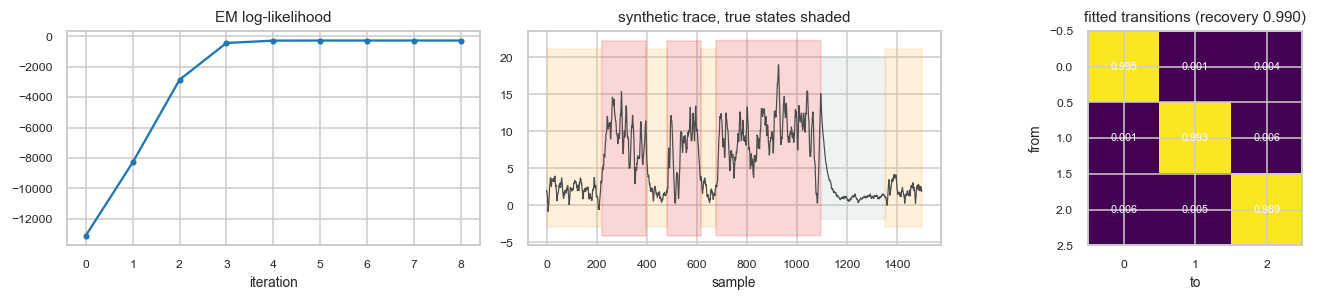

In [2]:
K, D, L = 3, 1, 2
W_true = np.zeros((K, D, D * L + 1))
W_true[0, 0] = [0.95,  0.00, 0.05]     # rest: slow decay to a low set point, tiny innovations
W_true[1, 0] = [1.30, -0.40, 0.20]     # intermediate: mild oscillation
W_true[2, 0] = [1.60, -0.65, 0.50]     # active: strong momentum, large innovations
S_true = np.array([[[0.01]], [[0.09]], [[0.36]]])
P_true = np.array([[0.995, 0.004, 0.001], [0.006, 0.990, 0.004], [0.001, 0.006, 0.993]])

gen = bs.StickyARHMM(K, L)
y_syn, z_syn = gen.simulate(60000, W_true, S_true, P_true, seed=1)
m_syn = bs.StickyARHMM(K, L, dwell_target_samples=100, prior_strength=0.01, seed=0)
m_syn.fit([y_syn], n_iter=100, n_restarts=2)

syn_ll = np.array(m_syn.fit_.ll_trace); syn_steps = np.diff(syn_ll)
z_hat = m_syn.decode(y_syn)
mapping, syn_acc = bs.match_states(z_syn, z_hat, K)
post = m_syn.posterior(y_syn)
agree = float(np.mean(np.argmax(post, 1) == z_hat))

# ar_order=0 must reduce exactly to a Gaussian HMM
Wg = np.zeros((2, 1, 1)); Wg[0, 0, 0], Wg[1, 0, 0] = -1.5, 1.5
Sg = np.array([[[0.25]], [[0.25]]]); Pg = np.array([[0.99, 0.01], [0.01, 0.99]])
yg, zg = bs.StickyARHMM(2, 0).simulate(20000, Wg, Sg, Pg, seed=3)
mg = bs.StickyARHMM(2, 0, dwell_target_samples=100, prior_strength=0.01, seed=0).fit([yg], n_iter=60, n_restarts=1)
_, syn_acc_g = bs.match_states(zg, mg.decode(yg), 2)

val = [
    ("EM likelihood is monotone",        bool((syn_steps >= -1e-6 * np.abs(syn_ll[:-1])).all()), f"min step {syn_steps.min():+.2e}"),
    ("state path recovered (AR-HMM)",    syn_acc > 0.85,   f"accuracy {syn_acc:.4f}"),
    ("Viterbi agrees with posterior",    agree > 0.95, f"agreement {agree:.4f}"),
    ("posterior rows sum to 1",          bool(np.allclose(post.sum(1), 1)), ""),
    ("ar_order=0 is a Gaussian HMM",     syn_acc_g > 0.90, f"accuracy {syn_acc_g:.4f}"),
]
display(pd.DataFrame([dict(check=c, result="PASS" if ok else "FAIL", detail=d) for c, ok, d in val]))

rec = []
for k in range(K):
    kk = int(np.flatnonzero(mapping == k)[0])
    rec.append(dict(state=k, W_true=np.round(W_true[k, 0], 3), W_fit=np.round(m_syn.fit_.W[kk, 0], 3),
                    sd_true=round(float(np.sqrt(S_true[k, 0, 0])), 3),
                    sd_fit=round(float(np.sqrt(m_syn.fit_.Sigma[kk, 0, 0])), 3)))
print("Parameter recovery (fitted vs the values used to generate the data):")
display(pd.DataFrame(rec))

fig, axes = plt.subplots(1, 3, figsize=(13, 2.9))
axes[0].plot(syn_ll, "o-", ms=3); axes[0].set(title="EM log-likelihood", xlabel="iteration")
sl = slice(2000, 3500)
axes[1].plot(y_syn[sl, 0], color="0.3", lw=0.8)
for k in range(K):
    m_ = z_syn[sl] == k
    axes[1].fill_between(np.arange(sl.stop - sl.start), *axes[1].get_ylim(), where=m_, alpha=0.2,
                         color=list(L1_COLORS.values())[k], step="mid")
axes[1].set(title="synthetic trace, true states shaded", xlabel="sample")
axes[2].imshow(np.exp(m_syn.fit_.log_P), cmap="viridis", vmin=0, vmax=1)
axes[2].set(title=f"fitted transitions (recovery {syn_acc:.3f})", xlabel="to", ylabel="from")
for i in range(K):
    for j in range(K):
        axes[2].text(j, i, f"{np.exp(m_syn.fit_.log_P)[i,j]:.3f}", ha="center", va="center",
                     color="w", fontsize=7)
show(fig, "S5_validation")

## 6 · Build the dataset

One pass per day per animal: the cursor (binned, z-scored), the behavioural covariates, and the task
structure (in-trial, reward, block). Everything is binned to the Level-1 rate so it shares one time
base. Each day is split into contiguous finite runs; runs shorter than `MIN_SEG_SEC` are dropped.

Covariates are carried alongside but are **never used to fit** either model.

In [3]:
def day_block_labels(trials, n_frames):
    '''Per-frame block label; remapping days are (intuitive, new, washout), others single.'''
    blocks = na.segment_factor_blocks(trials)
    lab = np.array(["single"] * n_frames, dtype=object)
    phase = "stable"
    if len(blocks) == 3:
        phase = "remap"
        names = ["intuitive_pre", "new", "washout"]
        for nm, b in zip(names, blocks):
            s = int(trials.start[b.first_trial])
            e = int(trials.start[b.last_trial]) if b.last_trial + 1 < len(trials.start) else n_frames
            e = min(max(e, s + 1), n_frames)
            lab[s:e] = nm
        lab[:int(trials.start[blocks[0].first_trial])] = "intuitive_pre"
        lab[int(trials.start[blocks[2].first_trial]):] = "washout"
    return lab, phase

def build_dataset():
    segs = []
    for mouse in MICE:
        r = na.open_mouse(rfs, DATA_ROOT, mouse)
        days = na.get_day_list(r)
        d0 = r["date_day0"].load()
        d0 = str(np.asarray(d0).ravel()[0]) if not isinstance(d0, str) else d0
        d0i = days.index(d0) if d0 in days else 0
        for di, day in enumerate(tqdm(days, desc=mouse, leave=False)):
            try:
                cur = ca.load_cursor_signal(r, day, column=CURSOR_COLUMN, transform=CURSOR_TRANSFORM,
                                            max_gap_sec=MAX_GAP_SEC, sr=SR)
            except Exception:
                continue
            n = len(cur)
            trials = na.get_true_bmi_trials(na.get_trials_df(r, day))
            if len(trials) == 0:
                continue
            rew_f = na.get_active_reward_frames(r, day)
            eff = na.effective_trial_end(trials, reward_frames=rew_f, miss_dur_sec=20.0, sr=SR)
            in_trial = np.zeros(n); in_hit = np.zeros(n); rew = np.zeros(n)
            # trial-level markers, so state naming can use trial rate and trial duration rather
            # than cursor statistics alone (a window fully inside one 20 s miss would otherwise
            # report a "mean duration" of 20 s and tell us nothing)
            t_start = np.zeros(n); dur_at_start = np.zeros(n)
            for s, e, su in zip(trials.start, eff, trials.success):
                a, b = int(s), min(int(e), n)
                if b > a:
                    in_trial[a:b] = 1.0
                    t_start[a] = 1.0; dur_at_start[a] = (b - a) / SR
                    if su == 1: in_hit[a:b] = 1.0
            ri = np.round(np.asarray(rew_f, float)); ri = ri[(ri >= 0) & (ri < n)].astype(int)
            rew[ri] = 1.0
            blk, phase = day_block_labels(trials, n)

            raw = dict(in_trial=in_trial, in_hit=in_hit,
                       treadmill=bs.load_treadmill_speed(r, day, sr=SR),
                       lick=bs.load_lick_rate(r, day, sr=SR, n_frames=n),
                       mc_motion=bs.load_mc_motion(r, day, sr=SR))
            C = {k: bs.bin_signal(v, BIN_L1) for k, v in raw.items()}
            for k, v in [("reward", rew), ("t_start", t_start), ("dur_at_start", dur_at_start)]:
                C[k] = bs.bin_signal(v, BIN_L1, "sum")      # counts must be summed, not averaged
            blk_b = np.array([blk[min(i * BIN_L1, n - 1)] for i in range(len(C["reward"]))], dtype=object)

            cb = bs.bin_signal(cur, BIN_L1)
            mu, sd = np.nanmean(cb), np.nanstd(cb)
            z = (cb - mu) / (sd if sd > 1e-9 else 1.0)
            for (s, e) in bs.contiguous_finite_segments(z, min_len=int(MIN_SEG_SEC * SR_L1)):
                segs.append(dict(mouse=mouse, day=str(day), day_idx=di, day_from0=di - d0i, phase=phase,
                                 start_bin=s, y=z[s:e].astype(np.float32),
                                 cov={k: np.asarray(v[s:e], np.float32) for k, v in C.items()},
                                 block=blk_b[s:e]))
    return segs

cache = OUT / f"segments_{CURSOR_COLUMN}_{CURSOR_TRANSFORM}_bin{BIN_L1}_v2.npz"
if USE_CACHE and cache.exists():
    _z = np.load(cache, allow_pickle=True); SEGS = list(_z["segs"])
else:
    t0 = time.time(); SEGS = build_dataset()
    np.savez_compressed(cache, segs=np.array(SEGS, dtype=object))
    print(f"built in {time.time()-t0:.0f}s")

seg_df = pd.DataFrame([{k: s[k] for k in ("mouse", "day", "day_idx", "day_from0", "phase")}
                       | {"minutes": len(s["y"]) / SR_L1 / 60} for s in SEGS])
print(f"{len(SEGS)} segments | {seg_df.minutes.sum()/60:.1f} h total | {SR_L1:.0f} Hz time base")
display(seg_df.groupby(["mouse", "phase"]).agg(days=("day", "nunique"), segments=("day", "size"),
                                               hours=("minutes", lambda v: round(v.sum()/60, 1))))

76 segments | 69.1 h total | 3 Hz time base


days  segments  hours
mouse       phase                        
mouse_0322R stable    30        34   29.4
mouse_0403L remap     15        15   16.6
            stable    20        21   17.7
mouse_0403R stable     4         4    3.5
mouse_0916N stable     2         2    1.8

## 7 · Level 1 — control states

Sticky AR-HMM on the binned, z-scored cursor, fitted **per animal** (so state labels are comparable
across that animal's days) using all of its days jointly.

`K` is chosen by held-out log-likelihood with whole days held out. The scan is run on the primary
animal and on a capped number of days (`CV_MAX_DAYS`) purely for runtime; the chosen `K` is then
applied to every animal. Because held-out likelihood rises monotonically with `K` for nested-ish
model families, the **elbow** is what is read, not the maximum.

In [4]:
cv_fp = OUT / f"cv_L1_K{min(K_SCAN)}-{max(K_SCAN)}.csv"
prim = [s["y"][:, None] for s in SEGS if s["mouse"] == PRIMARY][:CV_MAX_DAYS]
if USE_CACHE and cv_fp.exists():
    cv_l1 = pd.read_csv(cv_fp)
else:
    t0 = time.time()
    cv_l1 = bs.cv_select_states(prim, K_SCAN, ar_order=AR_ORDER, n_folds=CV_FOLDS,
                                dwell_target_samples=DWELL_L1_SEC * SR_L1,
                                prior_strength=PRIOR_L1, n_iter=50, seed=SEED)
    cv_l1.to_csv(cv_fp, index=False); print(f"CV in {time.time()-t0:.0f}s")
display(cv_l1.round(4))
gain = np.diff(cv_l1.test_ll.to_numpy())
print(f"marginal held-out gain per extra state: {np.round(gain, 4)}")
print(f"K = {K_L1} is used below (elbow of the curve; set K_L1 in the config to change it).")

,K,train_ll,test_ll,test_ll_sem,n_folds
0,2,-0.2042,-0.2144,0.0253,4
1,3,-0.0998,-0.1162,0.0268,4
2,4,-0.0619,-0.0864,0.0230,4
3,5,-0.0036,-0.0321,0.0254,4
4,6,0.0178,-0.0091,0.0258,4


marginal held-out gain per extra state: [0.0982 0.0298 0.0542 0.023 ]
K = 3 is used below (elbow of the curve; set K_L1 in the config to change it).


In [5]:
def fit_level1(mouse):
    seqs = [s["y"][:, None] for s in SEGS if s["mouse"] == mouse]
    if not seqs: return None, None
    m = bs.StickyARHMM(K_L1, AR_ORDER, dwell_target_samples=DWELL_L1_SEC * SR_L1,
                       prior_strength=PRIOR_L1, seed=SEED)
    m.fit(seqs, n_iter=80, n_restarts=2)
    labs = [m.decode(s) for s in seqs]
    order = bs.order_states_by(m, seqs, labs, key="speed")     # canonical: quietest state first
    return m, [bs.apply_state_order(l, order) for l in labs]

L1 = {}
for mouse in MICE:
    t0 = time.time(); m, labs = fit_level1(mouse)
    if m is None: continue
    L1[mouse] = dict(model=m, labels=labs)
    idx = [i for i, s in enumerate(SEGS) if s["mouse"] == mouse]
    for i, lab in zip(idx, labs): SEGS[i]["l1"] = lab
    print(f"{mouse:14s} ll={m.fit_.loglik:12.0f} iters={m.fit_.n_iter:3d} "
          f"dwell(s)={np.round(m.expected_dwell()/SR_L1, 1)} ({time.time()-t0:.0f}s)")

mouse_0403L    ll=     -115135 iters= 80 dwell(s)=[2.1 2.2 1.7] (21s)
mouse_0322R    ll=       70923 iters= 58 dwell(s)=[2.9 3.  2.7] (13s)
mouse_0403R    ll=       -7299 iters= 70 dwell(s)=[1.7 3.4 1.3] (2s)
mouse_0916N    ll=         827 iters= 80 dwell(s)=[1.3 2.  1.6] (1s)


In [6]:
def pooled(mouse, key):
    return np.concatenate([s[key] for s in SEGS if s["mouse"] == mouse and "l1" in s])

rows = []
for mouse in L1:
    y = pooled(mouse, "y"); lab = pooled(mouse, "l1")
    cv = {k: np.concatenate([s["cov"][k] for s in SEGS if s["mouse"] == mouse and "l1" in s])
          for k in SEGS[0]["cov"]}
    spd = np.abs(np.diff(y, prepend=y[0]))
    dw = pd.concat([bs.dwell_segments(s["l1"]) for s in SEGS if s["mouse"] == mouse and "l1" in s])
    for k in range(K_L1):
        m_ = lab == k
        rows.append(dict(mouse=mouse, state=k, name=L1_NAMES[k], occupancy=m_.mean(),
                         cursor_level=y[m_].mean(), cursor_speed=spd[m_].mean(),
                         median_dwell_s=dw[dw.state == k].length.median() / SR_L1,
                         frac_in_trial=np.nanmean(cv["in_trial"][m_]),
                         reward_per_min=np.nanmean(cv["reward"][m_]) * SR_L1 * 60,
                         treadmill=np.nanmean(cv["treadmill"][m_]), lick_hz=np.nanmean(cv["lick"][m_])))
L1_TAB = pd.DataFrame(rows)
print("Level-1 control states. Columns left of the divider come from the cursor (what was fitted);")
print("frac_in_trial / reward_per_min / treadmill / lick_hz are EXTERNAL and were not used in fitting.")
display(L1_TAB.round(3))

Level-1 control states. Columns left of the divider come from the cursor (what was fitted);
frac_in_trial / reward_per_min / treadmill / lick_hz are EXTERNAL and were not used in fitting.


,mouse,state,name,occupancy,cursor_level,cursor_speed,median_dwell_s,frac_in_trial,reward_per_min,treadmill,lick_hz
0,mouse_0403L,0,quiescent,0.232,-0.312,0.042,2.000,0.424,0.000000,0.315,0.337
1,mouse_0403L,1,slow,0.371,-0.446,0.166,2.333,0.366,0.843000,0.293,0.671
2,mouse_0403L,2,driving,0.397,0.599,0.642,2.333,0.418,10.398000,0.246,2.371
3,mouse_0322R,0,quiescent,0.290,-0.148,0.028,3.000,0.538,0.080000,0.423,0.083
4,mouse_0322R,1,slow,0.502,-0.269,0.149,3.333,0.553,0.249000,0.321,0.262
5,mouse_0322R,2,driving,0.208,0.855,0.591,2.667,0.474,7.287000,0.379,1.964
6,mouse_0403R,0,quiescent,0.639,-0.438,0.107,3.000,0.252,0.000000,0.646,0.141
7,mouse_0403R,1,slow,0.197,-0.188,0.608,0.667,0.288,0.000000,0.497,1.368
8,mouse_0403R,2,driving,0.164,1.931,0.758,1.333,0.487,26.080999,0.651,4.009
9,mouse_0916N,0,quiescent,0.233,-0.014,0.018,1.333,0.417,0.428000,0.285,1.057


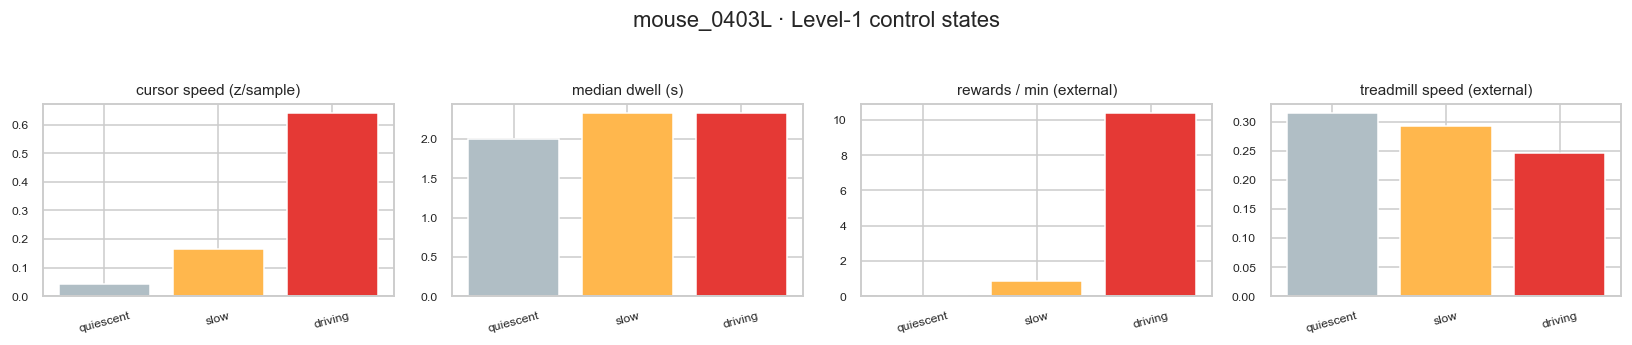

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.0))
sub = L1_TAB[L1_TAB.mouse == PRIMARY]
for ax, col, ttl in zip(axes, ["cursor_speed", "median_dwell_s", "reward_per_min", "treadmill"],
                        ["cursor speed (z/sample)", "median dwell (s)", "rewards / min (external)",
                         "treadmill speed (external)"]):
    ax.bar([L1_NAMES[k] for k in sub.state], sub[col], color=[L1_COLORS[k] for k in sub.state])
    ax.set(title=ttl); ax.tick_params(axis="x", rotation=15)
fig.suptitle(f"{PRIMARY} · Level-1 control states", y=1.04)
show(fig, "S7_L1_states")

## 8 · Level 2 — cursor-regime states

Features are computed in non-overlapping `WIN_SEC` windows from the **cursor only**, then z-scored
across all windows of an animal and fitted with a sticky Gaussian HMM (`ar_order=0`):

| feature | meaning |
|---|---|
| `cursor_speed` | mean \|Δcursor\| in the window — how much the cursor moved |
| `cursor_sd` | SD of the cursor — how wide its excursions were |
| `frac_quiescent` | fraction of the window with \|Δcursor\| < `QUIESCENT_DZ` — how much of it was dead time |
| `cursor_level` | mean cursor value — how high the tone sat |
| `L1_active_occ` | fraction of the window in the Level-1 *driving* state |

Reward, treadmill, licking and imaging motion are **excluded by construction**, which is what keeps
the comparison in Section 9 a real test.

States are put in a canonical order of **increasing cursor speed** so labels are stable across
refits. The names are descriptive labels read off the measured task profile below (and checked in
every animal); they are not an ordering by engagement — see Section 8b.

In [8]:
FEAT_NAMES = ["cursor_speed", "cursor_sd", "frac_quiescent", "cursor_level", "L1_active_occ"]
W_L2 = int(WIN_SEC * SR_L1)

def window_features(seg):
    y, l1 = seg["y"], seg["l1"]
    nb = len(y) // W_L2
    if nb < 3: return None
    Y = y[:nb * W_L2].reshape(nb, W_L2); L = l1[:nb * W_L2].reshape(nb, W_L2)
    dv = np.abs(np.diff(Y, axis=1))
    F = np.column_stack([dv.mean(1), Y.std(1), (dv < QUIESCENT_DZ).mean(1), Y.mean(1),
                         (L == K_L1 - 1).mean(1)])
    SUMS = {"reward", "t_start", "dur_at_start"}     # counts: sum over the window
    cov = {k: (v[:nb * W_L2].reshape(nb, W_L2).sum(1) if k in SUMS
               else v[:nb * W_L2].reshape(nb, W_L2).mean(1)) for k, v in seg["cov"].items()}
    cov["reward"] = cov["reward"] / WIN_SEC * 60                 # rewards per minute
    cov["trials_per_min"] = cov["t_start"] / WIN_SEC * 60        # trials STARTED per minute
    with np.errstate(invalid="ignore", divide="ignore"):
        # mean duration of the trials that START in this window (NaN if none did)
        cov["trial_dur_s"] = np.where(cov["t_start"] > 0, cov["dur_at_start"] / np.maximum(cov["t_start"], 1e-9), np.nan)
        cov["reward_per_trial"] = np.where(cov["t_start"] > 0,
                                           cov["reward"] * WIN_SEC / 60 / np.maximum(cov["t_start"], 1e-9), np.nan)
    blk = seg["block"][:nb * W_L2].reshape(nb, W_L2)[:, 0]
    return F, cov, blk

L2 = {}
for mouse in L1:
    packs = [(s, window_features(s)) for s in SEGS if s["mouse"] == mouse and "l1" in s]
    pack_seg_ids = [id(s) for s, p in packs if p is not None]
    packs = [(s, p) for s, p in packs if p is not None]
    if not packs: continue
    Fall = np.vstack([p[0] for _, p in packs])
    mu, sd = Fall.mean(0), Fall.std(0) + 1e-9
    feats = [(p[0] - mu) / sd for _, p in packs]
    m = bs.StickyARHMM(K_L2, 0, dwell_target_samples=DWELL_L2_WIN, prior_strength=PRIOR_L2, seed=SEED)
    m.fit(feats, n_iter=120, n_restarts=3)
    labs = [m.decode(f) for f in feats]
    # canonical order: least active first, by the cursor_speed feature
    order = bs.order_states_by(m, [f[:, :1] for f in feats], labs, key="level")
    labs = [bs.apply_state_order(l, order) for l in labs]
    L2[mouse] = dict(model=m, feats=feats, labels=labs,
                     cov=[p[1] for _, p in packs], block=[p[2] for _, p in packs],
                     meta=[{k: s[k] for k in ("day", "day_from0", "phase")} for s, _ in packs],
                     mu=mu, sd=sd, seg_ids=pack_seg_ids)
    dw = pd.concat([bs.dwell_segments(l) for l in labs])
    print(f"{mouse:14s} windows={sum(len(f) for f in feats):5d} "
          f"median dwell (min)={[round(dw[dw.state==k].length.median()*WIN_SEC/60, 1) for k in range(K_L2)]}")

mouse_0403L    windows= 8224 median dwell (min)=[np.float64(0.5), np.float64(0.5), np.float64(1.0), np.float64(1.0)]
mouse_0322R    windows= 7047 median dwell (min)=[np.float64(0.2), np.float64(0.5), np.float64(0.5), np.float64(0.5)]
mouse_0403R    windows=  844 median dwell (min)=[np.float64(0.2), np.float64(0.2), np.float64(0.8), np.float64(0.8)]
mouse_0916N    windows=  440 median dwell (min)=[np.float64(0.2), np.float64(0.5), np.float64(0.9), np.float64(0.5)]


In [9]:
rows = []
for mouse, P in L2.items():
    F = np.vstack(P["feats"]); lab = np.concatenate(P["labels"])
    cov = {k: np.concatenate([c[k] for c in P["cov"]]) for k in P["cov"][0]}
    dw = pd.concat([bs.dwell_segments(l) for l in P["labels"]])
    for k in range(K_L2):
        m_ = lab == k
        rec = dict(mouse=mouse, state=k, name=L2_NAMES[k], occupancy=m_.mean(),
                   median_dwell_min=dw[dw.state == k].length.median() * WIN_SEC / 60)
        rec |= {f: F[m_, i].mean() for i, f in enumerate(FEAT_NAMES)}
        rec |= dict(reward_per_min=np.nanmean(cov["reward"][m_]),
                    trials_per_min=np.nanmean(cov["trials_per_min"][m_]),
                    trial_dur_s=np.nanmean(cov["trial_dur_s"][m_]),
                    reward_per_trial=np.nanmean(cov["reward_per_trial"][m_]),
                    frac_in_trial=np.nanmean(cov["in_trial"][m_]),
                    treadmill=np.nanmean(cov["treadmill"][m_]),
                    lick_hz=np.nanmean(cov["lick"][m_]),
                    mc_motion=np.nanmean(cov["mc_motion"][m_]))
        rows.append(rec)
L2_TAB = pd.DataFrame(rows)
print("Level-2 cursor-regime states. The five feature columns were FITTED; everything from")
print("reward_per_min rightwards is an EXTERNAL hold-out and is what the state names are read from.")
display(L2_TAB.round(3))

print("Task profile of each state for the primary animal -- this is the evidence for the names.")
print("Note the names are NOT a single engagement ladder: two states can both be productive and")
print("differ only in cursor dynamics. Section 8b tests what that difference corresponds to.")
display(L2_TAB[L2_TAB.mouse == PRIMARY][
    ["state", "name", "occupancy", "reward_per_min", "trials_per_min", "trial_dur_s",
     "reward_per_trial", "cursor_speed", "frac_quiescent"]].round(3))

# The names are attached BY POSITION in the canonical order (increasing cursor speed), which is
# well defined for every animal -- but whether each position carries the same task profile in every
# animal is an empirical question, not something to assume. Check it explicitly.
print("\nreward/min per state, per animal (states ordered by increasing cursor speed):")
piv = L2_TAB.pivot_table(index="mouse", columns="name", values="reward_per_min").reindex(columns=L2_NAMES)
display(piv.round(2))
NAME_OK = {}
for mouse in piv.index:
    row = piv.loc[mouse]
    NAME_OK[mouse] = dict(
        idle_is_lowest=bool(row.idxmin() == "idle"),
        best_is_fluent_or_vigorous=bool(row.idxmax() in ("fluent", "vigorous")))
name_chk = pd.DataFrame(NAME_OK).T
display(name_chk)
if not name_chk.all().all():
    print("NOTE: in the animals marked False the positional name does NOT match the task profile.")
    print("Read the per-animal table above rather than the label for those animals.")
else:
    print("In every animal the lowest-yield state is 'idle' and the highest-yield state is")
    print("'fluent' or 'vigorous', so the positional names carry the intended meaning.")

Level-2 cursor-regime states. The five feature columns were FITTED; everything from
reward_per_min rightwards is an EXTERNAL hold-out and is what the state names are read from.


,mouse,state,name,occupancy,median_dwell_min,cursor_speed,cursor_sd,frac_quiescent,cursor_level,L1_active_occ,reward_per_min,trials_per_min,trial_dur_s,reward_per_trial,frac_in_trial,treadmill,lick_hz,mc_motion
0,mouse_0403L,0,idle,0.181,0.500,-1.414,-1.333,1.078,-0.478,-1.250,1.013,1.981,11.912,0.391,0.417,0.353,0.454,0.787
1,mouse_0403L,1,sporadic,0.223,0.500,-0.043,-0.108,-0.548,-1.050,-0.124,1.779,2.241,8.825,0.644,0.317,0.358,0.709,0.869
2,mouse_0403L,2,fluent,0.373,1.000,0.189,0.519,0.186,0.560,0.024,6.221,6.236,5.434,1.013,0.440,0.198,1.577,0.748
3,mouse_0403L,3,searching,0.223,1.000,0.878,0.325,-0.639,0.505,1.102,6.913,6.979,4.185,1.035,0.401,0.278,1.978,0.989
4,mouse_0322R,0,idle,0.280,0.250,-0.994,-1.108,0.756,-0.522,-0.956,0.002,1.671,18.666,0.001,0.604,0.327,0.006,0.500
5,mouse_0322R,1,sporadic,0.216,0.500,-0.086,-0.065,-0.489,-0.002,0.005,1.445,2.242,12.856,0.449,0.466,0.336,0.399,0.599
6,mouse_0322R,2,fluent,0.435,0.500,0.452,0.594,-0.193,0.458,0.359,2.900,3.821,10.799,0.672,0.564,0.387,1.027,0.610
7,mouse_0322R,3,searching,0.070,0.500,1.443,0.947,-0.318,-0.750,1.586,1.317,1.707,11.676,0.581,0.246,0.432,0.436,0.627
8,mouse_0403R,0,idle,0.209,0.250,-1.325,-1.553,0.067,-1.294,-1.288,0.000,0.477,15.232,0.000,0.334,0.709,0.037,0.906
9,mouse_0403R,1,sporadic,0.200,0.250,-0.577,-0.294,-0.031,-0.485,-0.601,1.893,2.722,7.152,0.625,0.256,0.648,0.503,0.889


Task profile of each state for the primary animal -- this is the evidence for the names.
Note the names are NOT a single engagement ladder: two states can both be productive and
differ only in cursor dynamics. Section 8b tests what that difference corresponds to.


,state,name,occupancy,reward_per_min,trials_per_min,trial_dur_s,reward_per_trial,cursor_speed,frac_quiescent
0,0,idle,0.181,1.013,1.981,11.912,0.391,-1.414,1.078
1,1,sporadic,0.223,1.779,2.241,8.825,0.644,-0.043,-0.548
2,2,fluent,0.373,6.221,6.236,5.434,1.013,0.189,0.186
3,3,searching,0.223,6.913,6.979,4.185,1.035,0.878,-0.639



reward/min per state, per animal (states ordered by increasing cursor speed):


name,idle,sporadic,fluent,searching
mouse,,,,
mouse_0322R,0.00,1.44,2.90,1.32
mouse_0403L,1.01,1.78,6.22,6.91
mouse_0403R,0.00,1.89,4.27,8.42
mouse_0916N,0.33,4.34,6.35,3.00


,idle_is_lowest,best_is_fluent_or_vigorous
mouse_0322R,True,True
mouse_0403L,True,False
mouse_0403R,True,False
mouse_0916N,True,True


NOTE: in the animals marked False the positional name does NOT match the task profile.
Read the per-animal table above rather than the label for those animals.


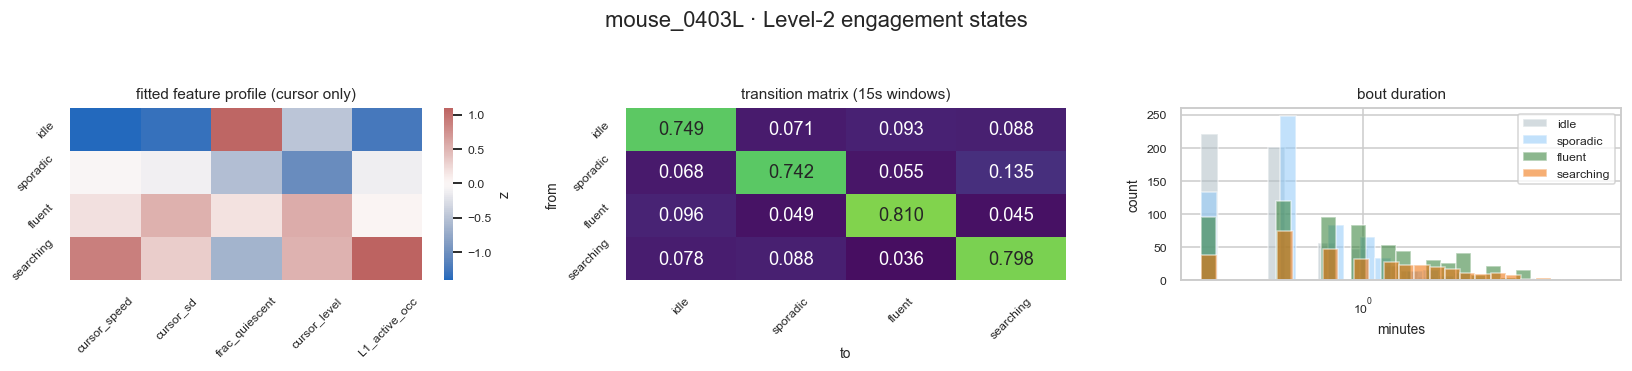

In [10]:
P = L2[PRIMARY]
F = np.vstack(P["feats"]); lab = np.concatenate(P["labels"])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
prof = pd.DataFrame(F, columns=FEAT_NAMES).groupby(lab).mean()
sns.heatmap(prof, cmap="vlag", center=0, ax=axes[0], cbar_kws=dict(label="z"),
            yticklabels=[L2_NAMES[k] for k in prof.index])
axes[0].set(title="fitted feature profile (cursor only)", ylabel="")
axes[0].tick_params(axis='y', rotation=45)
axes[0].tick_params(axis='x', rotation=45)
Pm = P["model"].transition_matrix()
sns.heatmap(Pm, annot=True, fmt=".3f", cmap="viridis", vmin=0, vmax=1, ax=axes[1],
            xticklabels=L2_NAMES, yticklabels=L2_NAMES, cbar=False)
axes[1].set(title=f"transition matrix ({WIN_SEC:.0f}s windows)", xlabel="to", ylabel="from")
axes[1].tick_params(axis='both', rotation=45)
dw = pd.concat([bs.dwell_segments(l) for l in P["labels"]])
for k in range(K_L2):
    d = dw[dw.state == k].length * WIN_SEC / 60
    axes[2].hist(d, bins=np.logspace(np.log10(WIN_SEC/60), np.log10(max(d.max(), 1)), 25),
                 alpha=0.55, color=L2_COLORS[k], label=L2_NAMES[k])
axes[2].set(xscale="log", title="bout duration", xlabel="minutes", ylabel="count"); axes[2].legend()

fig.suptitle(f"{PRIMARY} · Level-2 engagement states", y=1.05)
show(fig, "S8_L2_states")

In [22]:
s

{'mouse': 'mouse_0403L',
 'day': '20230729',
 'day_idx': 25,
 'day_from0': 25,
 'phase': 'remap',
 'start_bin': 5,
 'y': array([ 0.40766644,  0.6468858 ,  0.10452662, ..., -0.3252536 ,
        -0.54653573, -0.54985595], shape=(11861,), dtype=float32),
 'cov': {'in_trial': array([0., 0., 0., ..., 0., 0., 0.], shape=(11861,), dtype=float32),
  'in_hit': array([0., 0., 0., ..., 0., 0., 0.], shape=(11861,), dtype=float32),
  'treadmill': array([0.16487233, 0.17123908, 0.28599536, ..., 0.24409196, 0.01698906,
         0.00739472], shape=(11861,), dtype=float32),
  'lick': array([0. , 0. , 0. , ..., 1.9, 0.7, 0. ], shape=(11861,), dtype=float32),
  'mc_motion': array([0.7255814 , 1.3933333 , 1.04      , ..., 1.8133334 , 1.5133333 ,
         0.33333334], shape=(11861,), dtype=float32),
  'reward': array([0., 0., 0., ..., 0., 0., 0.], shape=(11861,), dtype=float32),
  't_start': array([0., 0., 0., ..., 0., 0., 0.], shape=(11861,), dtype=float32),
  'dur_at_start': array([0., 0., 0., ..., 0., 0

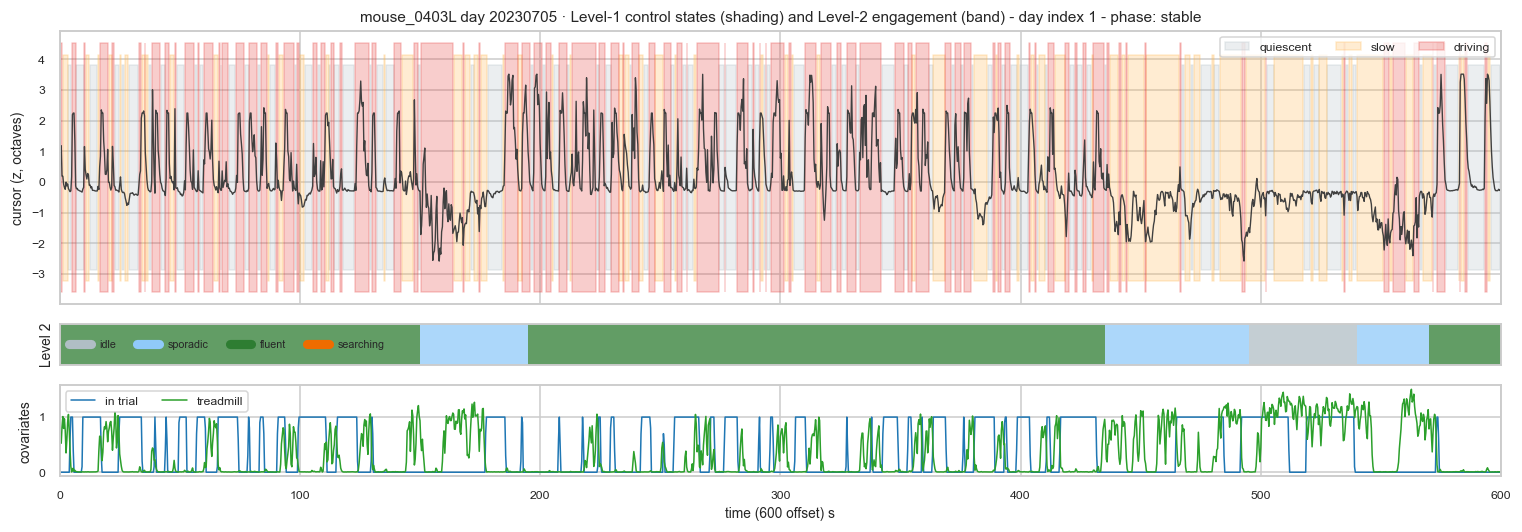

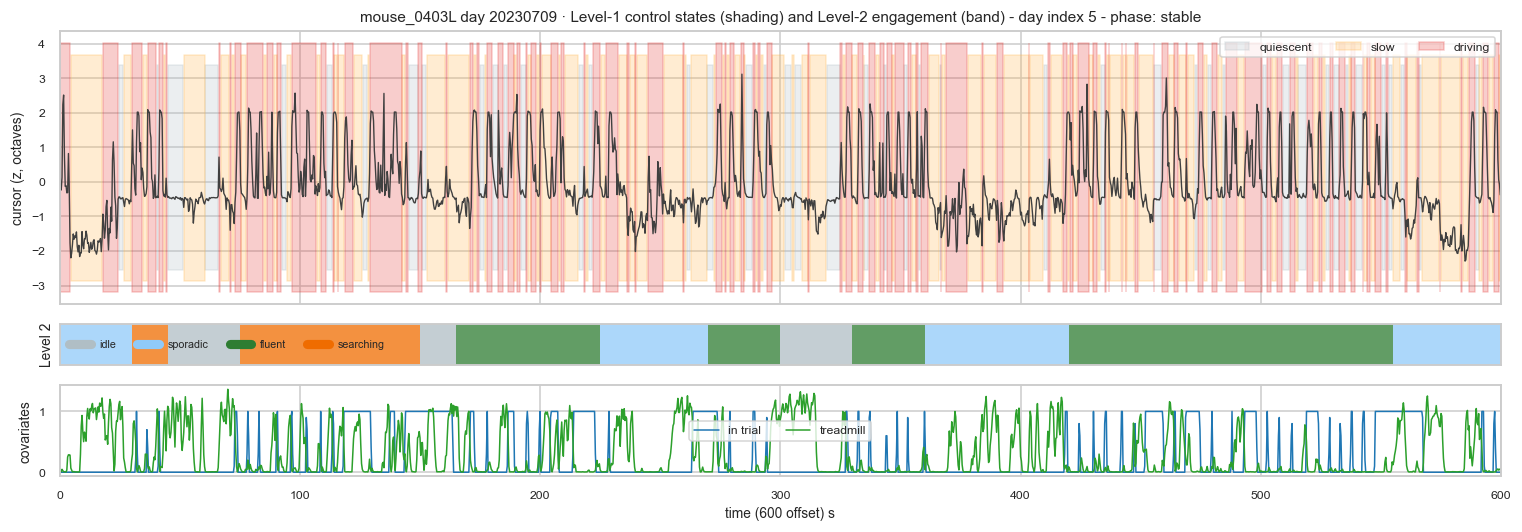

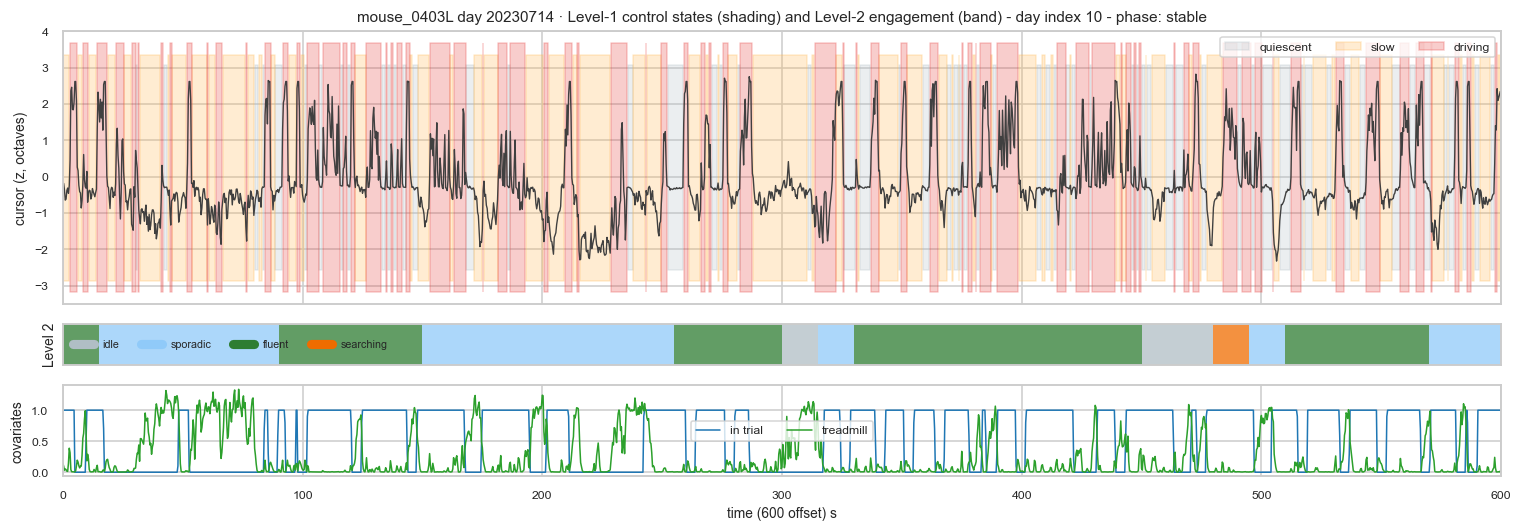

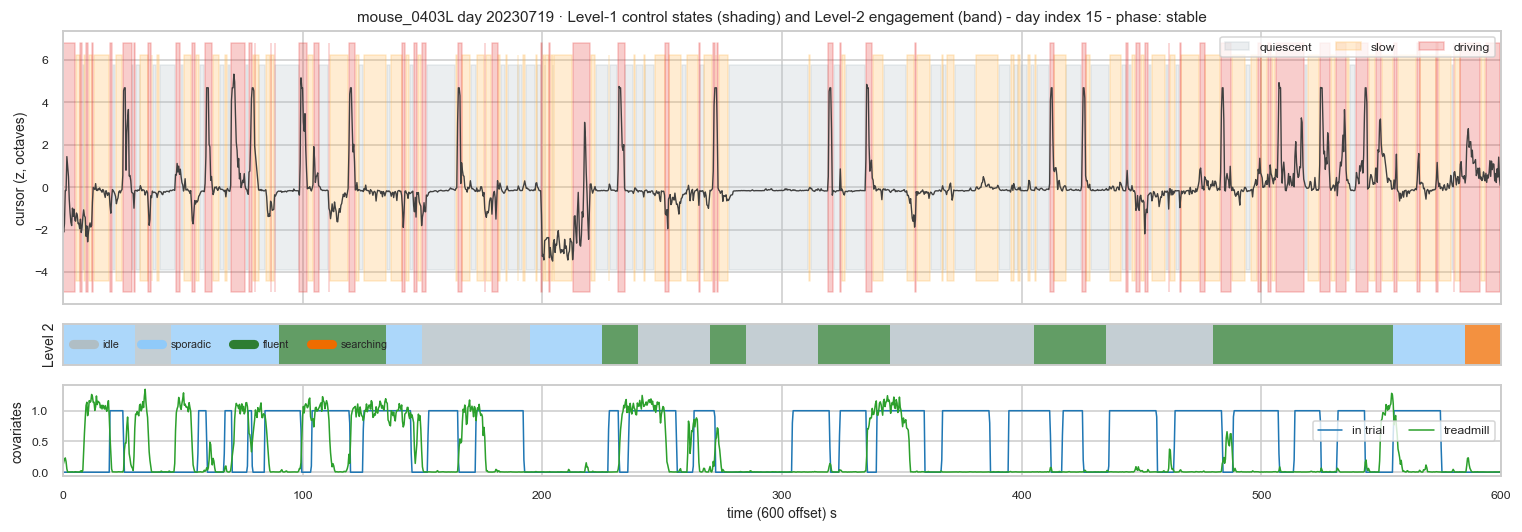

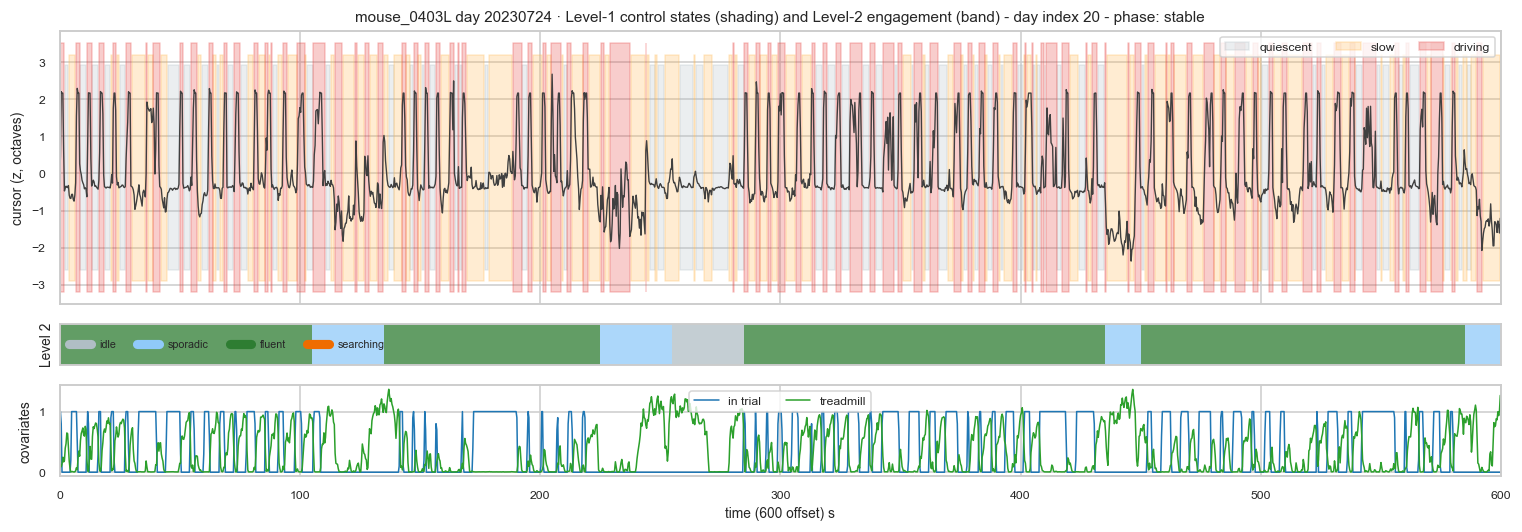

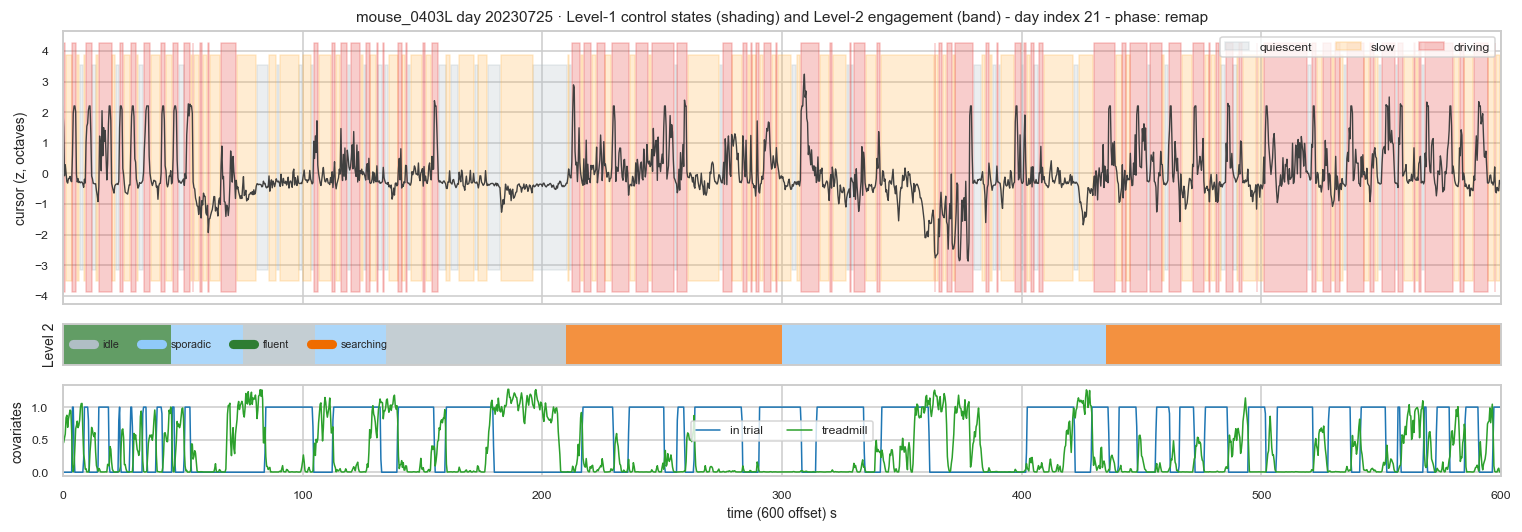

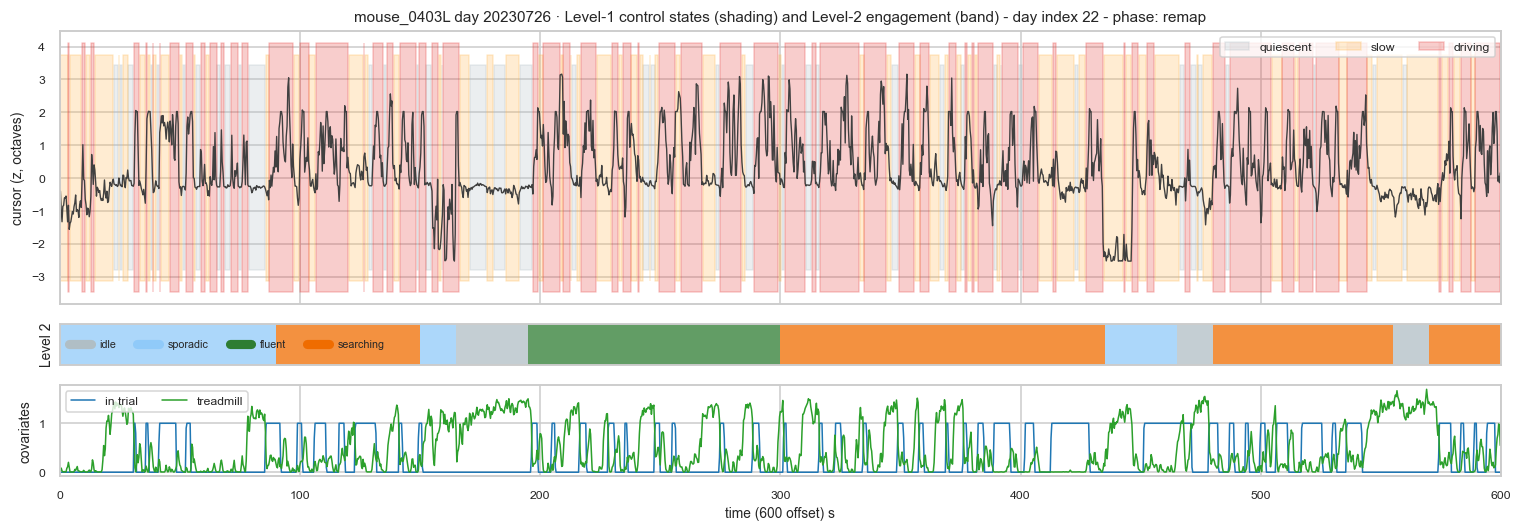

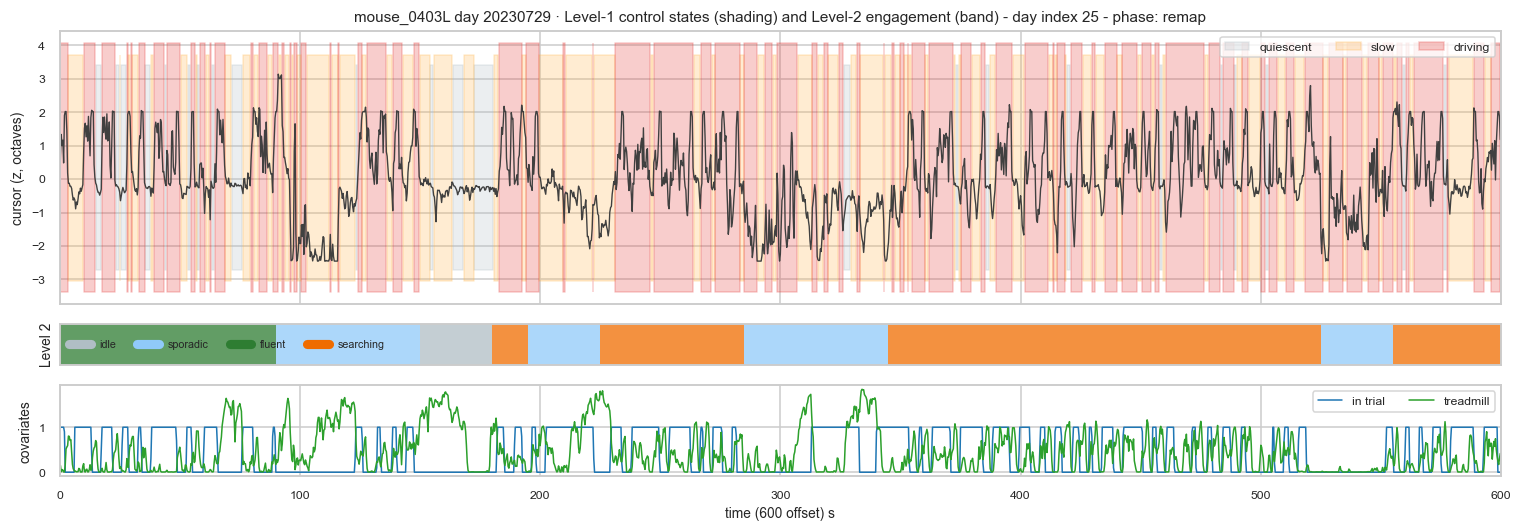

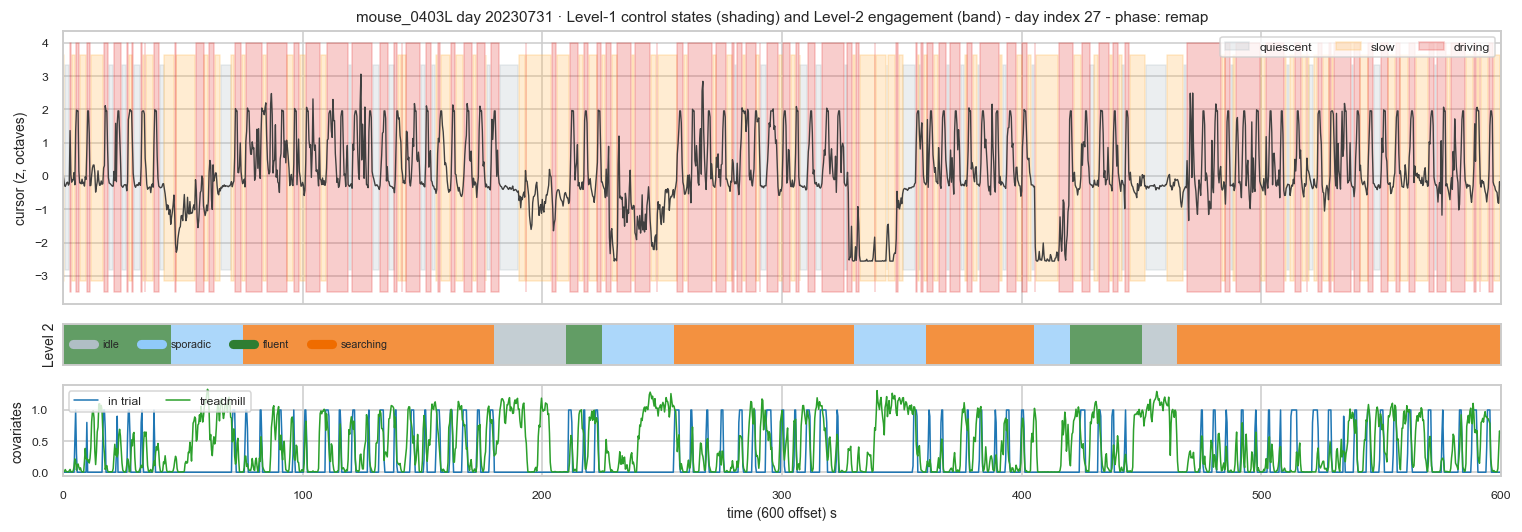

In [25]:
# Example trace showing BOTH timescales at once: the Level-1 control-state path shaded on the
# cursor, the Level-2 engagement state as a band beneath, and the covariates below that.
# Placed here rather than in Section 7 because it needs the Level-2 fit.
dayidx_list = [1, 5, 10, 15, 20, 21, 22, 25, 27]
for dayidx in dayidx_list:
    s = next(s for s in SEGS if s["mouse"] == PRIMARY and "l1" in s and  s['day_idx'] == dayidx)
    n_show = int(600 * SR_L1); off = int(600 * SR_L1)
    t = np.arange(n_show) / SR_L1
    fig, axes = plt.subplots(3, 1, figsize=(14, 5.0), sharex=True,
                             gridspec_kw=dict(height_ratios=[3, 0.45, 1]))
    axes[0].plot(t, s["y"][off:off + n_show], color="0.25", lw=0.9)
    lab = s["l1"][off:off + n_show]
    for k in range(K_L1):
        axes[0].fill_between(t, *axes[0].get_ylim(), where=(lab == k), color=L1_COLORS[k],
                            alpha=0.25, step="mid", label=L1_NAMES[k])
    axes[0].legend(ncol=K_L1, loc="upper right"); axes[0].set(ylabel="cursor (z, octaves)",
                                                            title=f"{PRIMARY} day {s['day']} · Level-1 control states (shading) and Level-2 engagement (band) - day index {s['day_idx']} - phase: {s['phase']}")
    # Level-2 engagement over the same window, so both timescales are visible at once
    P0 = L2.get(PRIMARY)
    if P0 is not None and id(s) in P0["seg_ids"]:
        pi = P0["seg_ids"].index(id(s)); l2w = P0["labels"][pi]
        w0, w1 = off // W_L2, min(int(np.ceil((off + n_show) / W_L2)), len(l2w))
        for wi in range(w0, w1):
            axes[1].axvspan((wi * W_L2 - off) / SR_L1, ((wi + 1) * W_L2 - off) / SR_L1,
                            color=L2_COLORS[int(l2w[wi])], alpha=0.75, lw=0)
        for k in range(K_L2):
            axes[1].plot([], [], lw=6, color=L2_COLORS[k], label=L2_NAMES[k])
        axes[1].legend(ncol=K_L2, loc="center left", fontsize=7, frameon=False)
    axes[1].set(ylabel="Level 2", yticks=[], xlim=(0, n_show / SR_L1)); axes[1].grid(False)
    axes[2].plot(t, s["cov"]["in_trial"][off:off + n_show], color="tab:blue", lw=1, label="in trial")
    axes[2].plot(t, s["cov"]["treadmill"][off:off + n_show], color="tab:green", lw=1, label="treadmill")
    axes[2].set(xlabel=f"time ({off / SR_L1:.0f} offset) s", ylabel="covariates"); axes[2].legend(ncol=2)
    show(fig, "S8_two_level_trace")

## 8b · Audit: is one state doing two jobs?

Reading the day-by-day occupancy plot, the two productive states appear to **swap** at the onset of
the remapping phase. That is the signature of a state set that is too small — a single label being
reused for two behaviours that happen not to co-occur. This section tests that directly, rather
than assuming either way.

Four tests, each of which could have come out negative:

1. **Held-out likelihood vs K.** If `K` is too small, adding states should still buy real
   generalisation. Whole days are held out.
2. **Within-session block composition.** On a remapping day the session runs
   intuitive → *rotation* → new axis → washout. Comparing state occupancy between those blocks
   **inside the same session** controls for day, session length, satiety and time-on-task — all
   the things a stable-vs-remap comparison across days confounds. (It needs controlling: remapping
   sessions are 80 min long where earlier sessions are 60 min.)
3. **State homogeneity.** Take the windows assigned to one state and split them by block. If the
   state is a single behaviour, its *fitted features* should look the same in both halves.
4. **Generalisation gap.** Fit on stable days only, then score remapping days. If new-axis control
   is genuinely a different regime, a model that has never seen it should fit it much worse.

If the state set is adequate, test 2 shows similar composition across blocks, test 3 shows no
difference, and test 4 shows a small gap.

In [12]:
# --- test 1: how much does held-out likelihood keep improving with K? ---
kfp = OUT / f"cv_L2_{PRIMARY}_K{min(K_L2_SCAN)}-{max(K_L2_SCAN)}.csv"
P = L2[PRIMARY]
if USE_CACHE and kfp.exists():
    cv_l2 = pd.read_csv(kfp)
else:
    t0 = time.time()
    cv_l2 = bs.cv_select_states(P["feats"], K_L2_SCAN, ar_order=0, n_folds=CV_FOLDS,
                                dwell_target_samples=DWELL_L2_WIN, prior_strength=PRIOR_L2,
                                n_iter=100, n_restarts=2, seed=SEED)
    cv_l2.to_csv(kfp, index=False); print(f"K scan in {time.time()-t0:.0f}s")
cv_l2["gain_vs_prev"] = cv_l2.test_ll.diff()
display(cv_l2.round(4))
print("The largest single gain marks the elbow; gains after it are the granularity/parsimony trade-off.")

# --- test 2: refit at several K and look at WITHIN-SESSION block composition ---
blk_all = np.concatenate(P["block"])
ph_all = np.concatenate([[m["phase"]] * len(f) for m, f in zip(P["meta"], P["feats"])])
cov_all = {k: np.concatenate([c[k] for c in P["cov"]]) for k in P["cov"][0]}
GROUPS = [("stable days", ph_all == "stable"),
          ("remap: intuitive", blk_all == "intuitive_pre"),
          ("remap: new axis", blk_all == "new"),
          ("remap: washout", blk_all == "washout")]

comp = {}
for K in [k for k in [3, 4, 5, 6] if k <= max(K_L2_SCAN)]:
    mk = bs.StickyARHMM(K, 0, dwell_target_samples=DWELL_L2_WIN, prior_strength=PRIOR_L2, seed=SEED)
    mk.fit(P["feats"], n_iter=120, n_restarts=3)
    Lk = [mk.decode(f) for f in P["feats"]]
    ok = bs.order_states_by(mk, [f[:, :1] for f in P["feats"]], Lk, key="level")
    Ak = np.concatenate([bs.apply_state_order(x, ok) for x in Lk])
    rows = []
    for nm, m in GROUPS:
        rows.append(dict(group=nm, **{f"s{k}": float(np.mean(Ak[m] == k)) for k in range(K)}))
    rows.append(dict(group="-- reward/min", **{f"s{k}": float(np.nanmean(cov_all["reward"][Ak == k])) for k in range(K)}))
    rows.append(dict(group="-- trials/min", **{f"s{k}": float(np.nanmean(cov_all["trials_per_min"][Ak == k])) for k in range(K)}))
    comp[K] = (pd.DataFrame(rows).set_index("group"), Ak)
    print(f"\n=== K = {K} : state occupancy within each block (top rows sum to 1 across states) ===")
    display(comp[K][0].round(3))

,K,train_ll,test_ll,test_ll_sem,n_folds,gain_vs_prev
0,2,-4.9639,-4.9986,0.0532,4,NaN
1,3,-4.6923,-4.7456,0.0505,4,0.2529
2,4,-4.5014,-4.5545,0.0435,4,0.1912
3,5,-4.4256,-4.5184,0.0416,4,0.0360
4,6,-4.3592,-4.4524,0.0378,4,0.0661
5,7,-4.3107,-4.4125,0.0375,4,0.0399
6,8,-4.2640,-4.3660,0.0254,4,0.0465


The largest single gain marks the elbow; gains after it are the granularity/parsimony trade-off.

=== K = 3 : state occupancy within each block (top rows sum to 1 across states) ===


,s0,s1,s2
group,,,
stable days,0.264,0.574,0.162
remap: intuitive,0.289,0.565,0.147
remap: new axis,0.053,0.057,0.890
remap: washout,0.376,0.529,0.095
-- reward/min,0.872,6.164,4.549
-- trials/min,1.870,6.203,4.749



=== K = 4 : state occupancy within each block (top rows sum to 1 across states) ===


,s0,s1,s2,s3
group,,,,
stable days,0.234,0.199,0.546,0.021
remap: intuitive,0.263,0.133,0.533,0.072
remap: new axis,0.044,0.302,0.040,0.614
remap: washout,0.349,0.113,0.509,0.029
-- reward/min,1.013,1.779,6.221,6.913
-- trials/min,1.981,2.241,6.236,6.979



=== K = 5 : state occupancy within each block (top rows sum to 1 across states) ===


,s0,s1,s2,s3,s4
group,,,,,
stable days,0.231,0.187,0.525,0.042,0.015
remap: intuitive,0.267,0.128,0.524,0.012,0.069
remap: new axis,0.036,0.301,0.037,0.060,0.567
remap: washout,0.345,0.128,0.502,0.002,0.024
-- reward/min,1.025,2.004,6.279,2.701,7.107
-- trials/min,2.004,2.497,6.298,2.667,7.177



=== K = 6 : state occupancy within each block (top rows sum to 1 across states) ===


,s0,s1,s2,s3,s4,s5
group,,,,,,
stable days,0.124,0.226,0.151,0.404,0.076,0.019
remap: intuitive,0.168,0.183,0.078,0.423,0.081,0.067
remap: new axis,0.025,0.027,0.057,0.018,0.396,0.477
remap: washout,0.137,0.591,0.089,0.091,0.051,0.040
-- reward/min,0.000,4.067,1.779,6.662,2.820,7.320
-- trials/min,1.235,4.347,2.221,6.684,3.209,7.354


In [13]:
# --- test 3: is a single state homogeneous across blocks? ---
# Take the K=3 model's most active state (the one the day-plot showed swapping) and compare its
# windows from stable days against its windows from new-axis blocks, feature by feature.
A3 = comp[3][1]
TOP3 = 2                                       # top (fastest-cursor) state of the K=3 fit
a = (A3 == TOP3) & (ph_all == "stable")
b = (A3 == TOP3) & (blk_all == "new")
F_all = np.vstack(P["feats"])
print(f"K=3 state {TOP3}: {a.sum()} windows from stable days vs {b.sum()} from new-axis blocks")
rows = []
for i, f in enumerate(FEAT_NAMES):
    st = mannwhitneyu(F_all[a, i], F_all[b, i]) if min(a.sum(), b.sum()) > 10 else None
    rows.append(dict(feature=f, stable=F_all[a, i].mean(), new_axis=F_all[b, i].mean(),
                     difference=F_all[b, i].mean() - F_all[a, i].mean(),
                     p=(st.pvalue if st else np.nan)))
for nm in ["reward", "trials_per_min", "in_trial"]:
    rows.append(dict(feature=f"({nm}, external)", stable=np.nanmean(cov_all[nm][a]),
                     new_axis=np.nanmean(cov_all[nm][b]), difference=np.nan, p=np.nan))
display(pd.DataFrame(rows).round(4))
print("A state that is one behaviour should show no systematic difference between these columns.")

# --- test 4: does a stable-only model describe remapping days? ---
tr_idx = [i for i, m in enumerate(P["meta"]) if m["phase"] == "stable"]
te_idx = [i for i, m in enumerate(P["meta"]) if m["phase"] == "remap"]
gap_rows = []
if len(tr_idx) >= 6 and len(te_idx) >= 2:
    hold = tr_idx[-3:]; fitidx = tr_idx[:-3]
    new_windows = []
    for f, blk_seg in zip(P["feats"], P["block"]):
        m_new = (blk_seg == "new")
        if m_new.sum() > 10:
            new_windows.append(f[m_new])
    for K in [3, K_L2]:
        ms = bs.StickyARHMM(K, 0, dwell_target_samples=DWELL_L2_WIN, prior_strength=PRIOR_L2, seed=SEED)
        ms.fit([P["feats"][i] for i in fitidx], n_iter=120, n_restarts=2)
        gap_rows.append(dict(K=K,
                             held_out_stable=ms.loglik_per_sample([P["feats"][i] for i in hold]),
                             remap_days=ms.loglik_per_sample([P["feats"][i] for i in te_idx]),
                             new_axis_only=ms.loglik_per_sample(new_windows)))
    g = pd.DataFrame(gap_rows)
    g["gap_stable_minus_new"] = g.held_out_stable - g.new_axis_only
    display(g.round(4))
    print("Log-likelihood per sample under a model fitted on STABLE days only (higher = better fit).")
    print("A large drop from held_out_stable to new_axis_only means new-axis control is a regime")
    print("the stable-day model never saw -- i.e. it needs its own state(s).")

K=3 state 2: 688 windows from stable days vs 2431 from new-axis blocks


,feature,stable,new_axis,difference,p
0,cursor_speed,0.1276,0.6707,0.5431,0.0000
1,cursor_sd,0.1696,0.2166,0.0470,0.4992
2,frac_quiescent,-0.6348,-0.6624,-0.0276,0.0310
3,cursor_level,-0.8494,-0.0485,0.8009,0.0000
4,L1_active_occ,-0.0070,0.8352,0.8422,0.0000
5,"(reward, external)",2.6163,5.1798,NaN,NaN
6,"(trials_per_min, external)",2.7558,5.4134,NaN,NaN
7,"(in_trial, external)",0.2884,0.3879,NaN,NaN


A state that is one behaviour should show no systematic difference between these columns.


,K,held_out_stable,remap_days,new_axis_only,gap_stable_minus_new
0,3,-4.2928,-5.8282,-6.5263,2.2335
1,4,-4.2412,-5.7506,-6.4725,2.2313


Log-likelihood per sample under a model fitted on STABLE days only (higher = better fit).
A large drop from held_out_stable to new_axis_only means new-axis control is a regime
the stable-day model never saw -- i.e. it needs its own state(s).


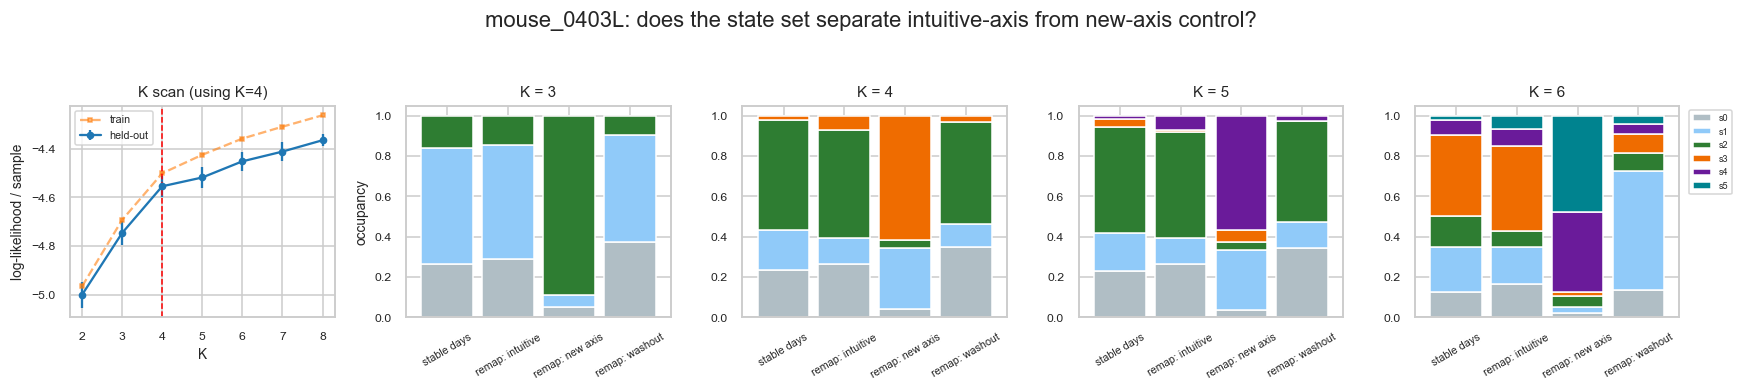

In [14]:
# --- summary figure for the audit ---
Ks = sorted(comp)
fig, axes = plt.subplots(1, len(Ks) + 1, figsize=(3.2 * (len(Ks) + 1), 3.4))
axes[0].errorbar(cv_l2.K, cv_l2.test_ll, yerr=cv_l2.test_ll_sem, marker="o", ms=4, label="held-out")
axes[0].plot(cv_l2.K, cv_l2.train_ll, "s--", ms=3, alpha=0.6, label="train")
axes[0].axvline(K_L2, color="r", ls="--", lw=1)
axes[0].set(xlabel="K", ylabel="log-likelihood / sample", title=f"K scan (using K={K_L2})")
axes[0].legend(fontsize=7)
for ax, K in zip(axes[1:], Ks):
    tab = comp[K][0].loc[[g for g, _ in GROUPS]]
    tab.plot(kind="bar", stacked=True, ax=ax, width=0.85, legend=False,
             color=[_L2_PAL[k % len(_L2_PAL)] for k in range(K)])
    ax.set(title=f"K = {K}", ylabel="occupancy" if K == Ks[0] else "", xlabel="")
    ax.tick_params(axis="x", rotation=30, labelsize=7)
axes[-1].legend([f"s{k}" for k in range(Ks[-1])], fontsize=6, bbox_to_anchor=(1.02, 1), loc="upper left")
fig.suptitle(f"{PRIMARY}: does the state set separate intuitive-axis from new-axis control?", y=1.04)
show(fig, "S8b_state_audit")

## 9 · Relationship to treadmill, licking and imaging motion

The heart of the multimodal comparison. Every quantity here was held out of both models, so any
structure is a genuine relationship rather than a restatement of the fitting inputs.

Four analyses:

1. **Treadmill transform validation** — re-run against imaging motion, so the choice of speed proxy
   is checked in-notebook rather than asserted.
2. **Covariates by state**, with Kruskal–Wallis across states (descriptive, uncorrected).
3. **Transition-triggered averages** — covariates aligned to entry into each engagement state, which
   shows whether locomotion and licking *lead* or *follow* the change in engagement.
4. **Cross-correlation** between cursor activity and treadmill speed at a range of lags.

In [15]:
# --- 1. treadmill transform validation, against imaging motion as an independent reference ---
r0 = na.open_mouse(rfs, DATA_ROOT, PRIMARY)
val_rows = []
for day in na.get_day_list(r0)[1:6]:
    ref = bs.load_mc_motion(r0, day, sr=SR)
    for mode in bs.TREADMILL_MODES:
        v = bs.load_treadmill_speed(r0, day, mode=mode, sr=SR)
        ok = np.isfinite(v) & np.isfinite(ref)
        val_rows.append(dict(day=day, mode=mode, spearman=spearmanr(v[ok], ref[ok]).statistic))
tv = pd.DataFrame(val_rows).groupby("mode").spearman.agg(["mean", "min", "max"]).round(3)
print("Treadmill speed proxy vs imaging motion (independent movement reference), 5 days:")
display(tv)
print("The three transforms behave alike, so the default 'abs_dev' sets the units, not the conclusions.")
print("The absolute value depends on the smoothing of BOTH signals (smooth_sec), so read it as a")
print("consistency check between two independent movement measures, not as a calibration.")

Treadmill speed proxy vs imaging motion (independent movement reference), 5 days:


,mean,min,max
mode,,,
abs_dev,0.477,0.441,0.575
abs_diff,0.480,0.445,0.580
rolling_sd,0.504,0.464,0.605


The three transforms behave alike, so the default 'abs_dev' sets the units, not the conclusions.
The absolute value depends on the smoothing of BOTH signals (smooth_sec), so read it as a
consistency check between two independent movement measures, not as a calibration.


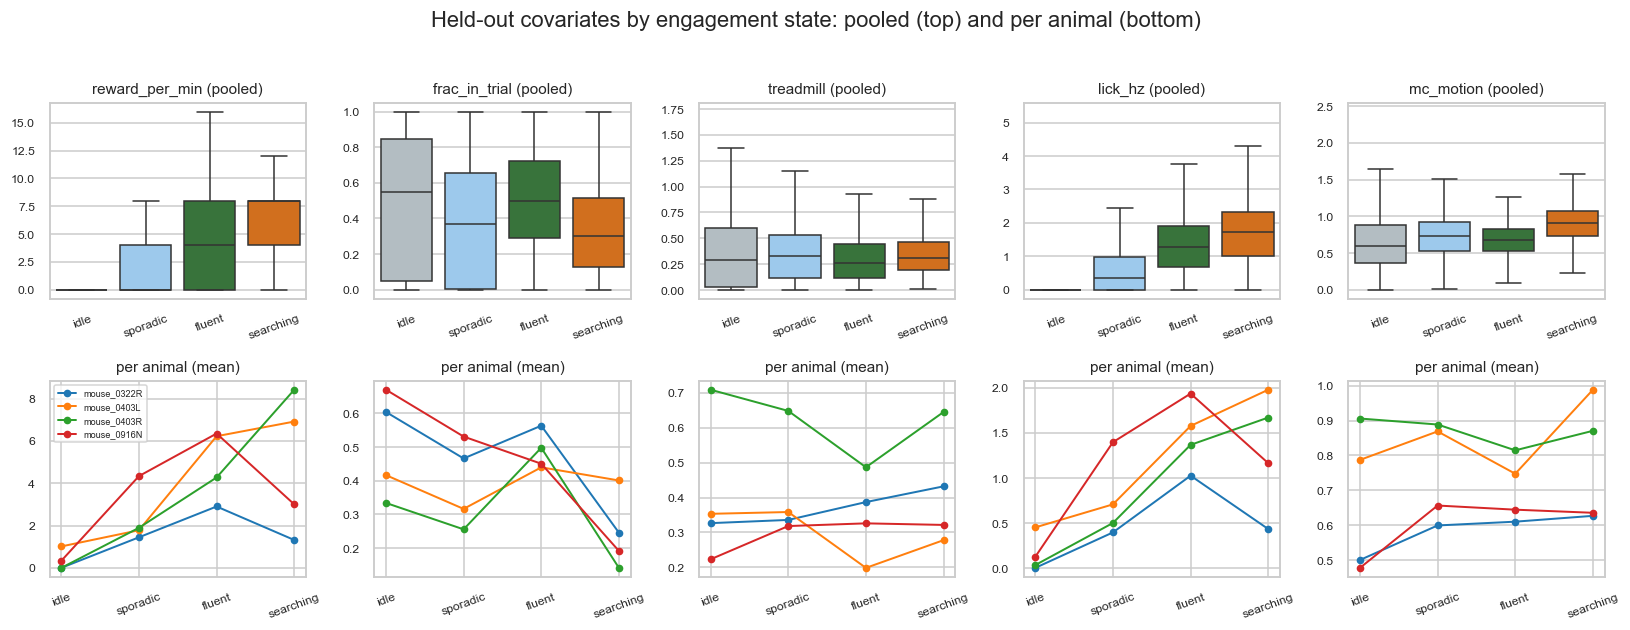

Kruskal-Wallis across engagement states (descriptive, uncorrected).
n_mice_monotone counts animals whose 3 state means are monotone -- a consistency check
that pooled significance alone does not give, since pooling can mask or manufacture effects.


,covariate,H_pooled,p_pooled,n_mice_p_lt_05,n_mice_monotone,n_mice,idle,sporadic,fluent,searching
0,reward_per_min,5567.923828,0.0,4,2,4,0.4142,1.7453,4.5844,5.9262
1,frac_in_trial,837.605408,0.0,4,1,4,0.5185,0.3842,0.5007,0.3394
2,treadmill,117.632797,0.0,4,1,4,0.3526,0.3609,0.2999,0.3455
3,lick_hz,6513.775879,0.0,4,2,4,0.1894,0.5977,1.3162,1.6393
4,mc_motion,1519.777344,0.0,4,1,4,0.6332,0.7497,0.6828,0.8995


In [16]:
# --- 2. covariates by engagement state, pooled over animals ---
# display name -> key in the per-window covariate dict (kept explicit; these differ)
COV_KEY = {"reward_per_min": "reward", "frac_in_trial": "in_trial", "treadmill": "treadmill",
           "lick_hz": "lick", "mc_motion": "mc_motion"}
COVS = list(COV_KEY)
fig, axes = plt.subplots(2, len(COVS), figsize=(3.0 * len(COVS), 5.6))
stat_rows = []
for ax, cname in zip(axes.T, COVS):
    vals = []
    for mouse, P in L2.items():
        lab = np.concatenate(P["labels"])
        cov = {k: np.concatenate([c[k] for c in P["cov"]]) for k in P["cov"][0]}
        src = cov[COV_KEY[cname]]
        for k in range(K_L2):
            for v in src[lab == k]:
                vals.append(dict(mouse=mouse, state=L2_NAMES[k], k=k, value=v))
    dfc = pd.DataFrame(vals)
    sns.boxplot(data=dfc, x="state", y="value", order=L2_NAMES, ax=ax[0], fliersize=0,
                palette=[L2_COLORS[k] for k in range(K_L2)])
    ax[0].set(title=f"{cname} (pooled)", xlabel="", ylabel="")
    ax[0].tick_params(axis="x", rotation=20)
    # pooling mixes animals with different baselines, which can mask a consistent
    # within-animal effect -- so show each animal separately as well
    pm = dfc.groupby(["mouse", "k"]).value.mean().unstack()
    for mouse in pm.index:
        ax[1].plot(range(K_L2), pm.loc[mouse], "-o", ms=4, lw=1.3, label=mouse)
    ax[1].set_xticks(range(K_L2)); ax[1].set_xticklabels(L2_NAMES, rotation=20)
    ax[1].set(title="per animal (mean)", ylabel="")
    groups = [dfc.loc[dfc.k == k, "value"].dropna().to_numpy() for k in range(K_L2)]
    if min(len(g) for g in groups) > 5:
        H, p = kruskal(*groups)
        # also test within each animal, then count how many agree in direction
        per_mouse_p, mono = [], 0
        for mouse in dfc.mouse.unique():
            gm = [dfc.loc[(dfc.k == k) & (dfc.mouse == mouse), "value"].dropna().to_numpy()
                  for k in range(K_L2)]
            if min(len(g) for g in gm) > 5:
                per_mouse_p.append(kruskal(*gm).pvalue)
                mono += int(np.all(np.diff([np.nanmean(g) for g in gm]) > 0)
                            or np.all(np.diff([np.nanmean(g) for g in gm]) < 0))
        stat_rows.append(dict(covariate=cname, H_pooled=H, p_pooled=p,
                              n_mice_p_lt_05=int(np.sum(np.array(per_mouse_p) < 0.05)),
                              n_mice_monotone=mono, n_mice=len(per_mouse_p),
                              **{L2_NAMES[k]: float(np.nanmean(groups[k])) for k in range(K_L2)}))
axes[1, 0].legend(fontsize=6)
fig.suptitle("Held-out covariates by engagement state: pooled (top) and per animal (bottom)", y=1.02)
show(fig, "S9_covariates_by_state")
print("Kruskal-Wallis across engagement states (descriptive, uncorrected).")
print("n_mice_monotone counts animals whose 3 state means are monotone -- a consistency check")
print("that pooled significance alone does not give, since pooling can mask or manufacture effects.")
display(pd.DataFrame(stat_rows).round(4))

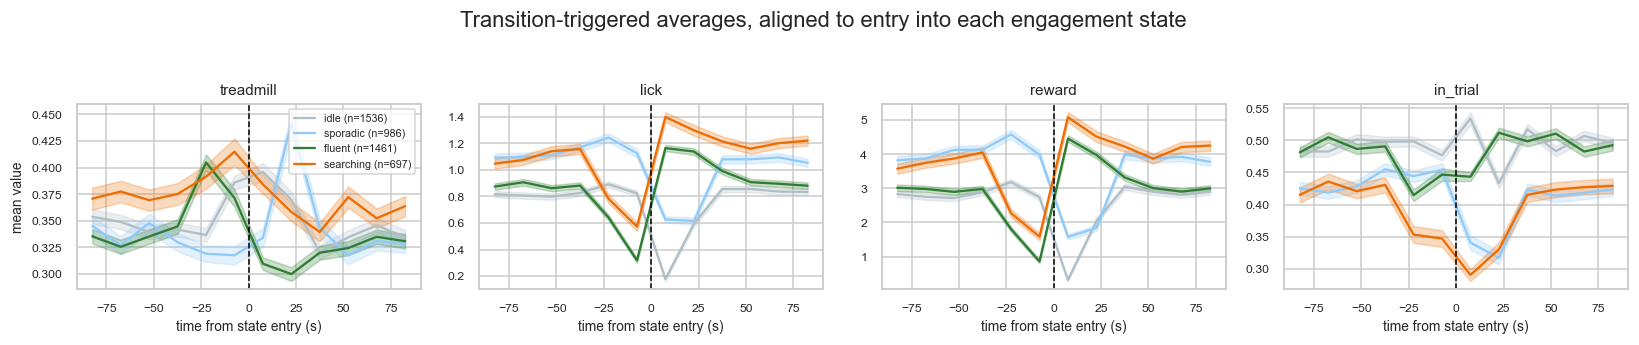

In [17]:
# --- 3. transition-triggered averages: what happens around a change in engagement? ---
HALF = int(round(90 / WIN_SEC))       # +/- 90 s, in windows
tta = {c: {k: [] for k in range(K_L2)} for c in ["treadmill", "lick", "reward", "in_trial"]}
for mouse, P in L2.items():
    for lab, cov in zip(P["labels"], P["cov"]):
        segd = bs.dwell_segments(lab)
        for _, row in segd.iterrows():
            s0, k = int(row.start), int(row.state)
            if s0 - HALF < 0 or s0 + HALF >= len(lab): continue
            for c in tta:
                tta[c][k].append(cov[c][s0 - HALF:s0 + HALF])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.0), sharex=True)
tt = (np.arange(-HALF, HALF) + 0.5) * WIN_SEC
for ax, c in zip(axes, ["treadmill", "lick", "reward", "in_trial"]):
    for k in range(K_L2):
        A = np.array(tta[c][k])
        if len(A) < 5: continue
        m_, se = A.mean(0), A.std(0) / np.sqrt(len(A))
        ax.plot(tt, m_, color=L2_COLORS[k], label=f"{L2_NAMES[k]} (n={len(A)})")
        ax.fill_between(tt, m_ - se, m_ + se, color=L2_COLORS[k], alpha=0.25)
    ax.axvline(0, color="k", ls="--", lw=1)
    ax.set(title=c, xlabel="time from state entry (s)")
axes[0].set_ylabel("mean value"); axes[0].legend(fontsize=7)
fig.suptitle("Transition-triggered averages, aligned to entry into each engagement state", y=1.04)
show(fig, "S9_transition_triggered")

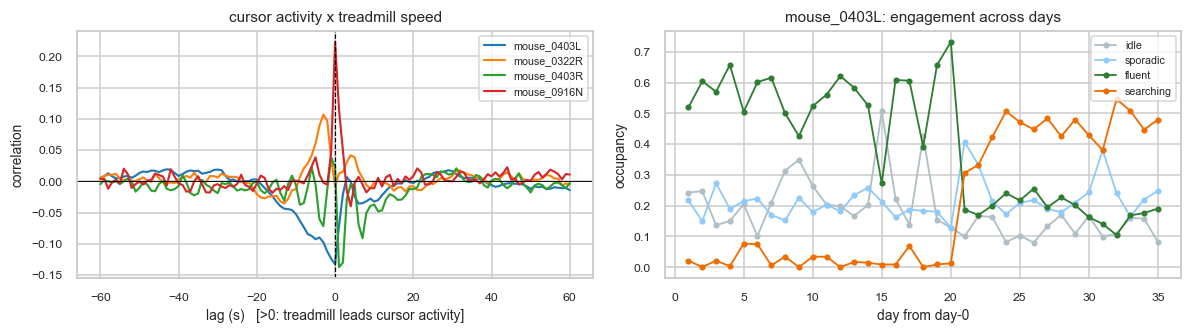

In [18]:
# --- 4. cross-correlation of cursor activity with treadmill speed ---
MAXLAG = int(round(60 * SR_L1))
lags = np.arange(-MAXLAG, MAXLAG + 1, max(1, int(SR_L1)))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
for mouse in L2:
    xc = []
    for s in [s for s in SEGS if s["mouse"] == mouse and "l1" in s][:12]:
        y = s["y"]; a = np.abs(np.diff(y, prepend=y[0])); b = s["cov"]["treadmill"]
        n = min(len(a), len(b)); a, b = a[:n], b[:n]
        a = (a - a.mean()) / (a.std() + 1e-9); b = (b - b.mean()) / (b.std() + 1e-9)
        xc.append([np.mean(a[max(0, -L_):n - max(0, L_)] * b[max(0, L_):n - max(0, -L_)]) for L_ in lags])
    A = np.array(xc)
    axes[0].plot(lags / SR_L1, A.mean(0), label=mouse, lw=1.4)
axes[0].axvline(0, color="k", ls="--", lw=0.8); axes[0].axhline(0, color="k", lw=0.6)
axes[0].set(xlabel="lag (s)   [>0: treadmill leads cursor activity]", ylabel="correlation",
            title="cursor activity x treadmill speed")
axes[0].legend(fontsize=7)
occ = []
for mouse, P in L2.items():
    for lab, meta in zip(P["labels"], P["meta"]):
        o = bs.state_occupancy(lab, K_L2)
        occ.append(dict(mouse=mouse, day_from0=meta["day_from0"], phase=meta["phase"],
                        **{L2_NAMES[k]: o[k] for k in range(K_L2)}))
OCC = pd.DataFrame(occ)
g = OCC[OCC.mouse == PRIMARY].groupby("day_from0")[L2_NAMES].mean()
g.plot(ax=axes[1], color=[L2_COLORS[k] for k in range(K_L2)], marker="o", ms=3, lw=1.2)
axes[1].set(xlabel="day from day-0", ylabel="occupancy", title=f"{PRIMARY}: engagement across days")
axes[1].legend(fontsize=7)
show(fig, "S9_xcorr_and_days")

## 10 · Cursor-regime states and task structure

Two questions the states are well placed to answer:

1. **Within a session**, does engagement decay with time on task?
2. **On remapping days**, how does engagement differ between the intuitive, new-axis and washout
   blocks? This bears directly on the standing caveat that washout is confounded with motivation —
   here that confound becomes something measured rather than assumed.

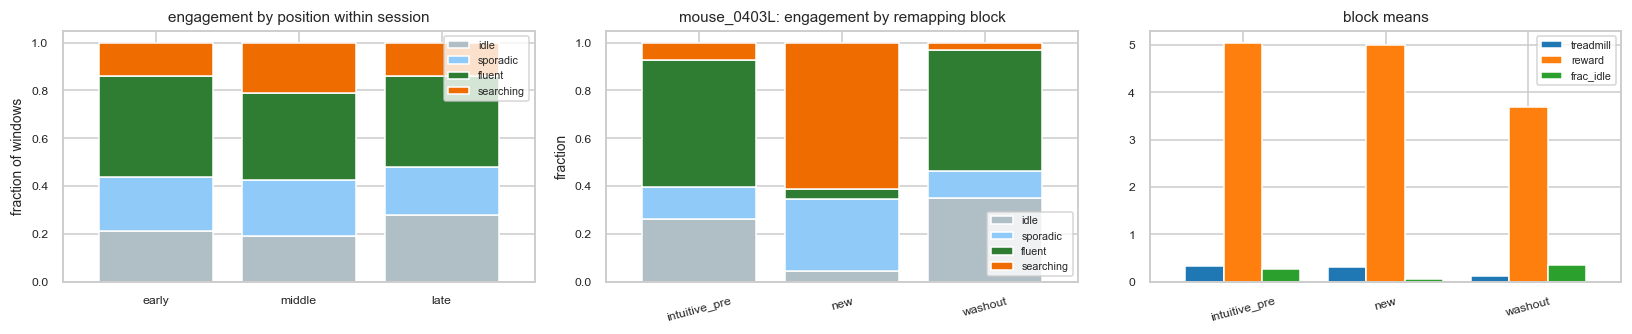

Engagement-state composition by remapping block (rows sum to 1):


,idle,sporadic,fluent,searching
block,,,,
intuitive_pre,0.263,0.133,0.533,0.072
new,0.044,0.302,0.040,0.614
washout,0.349,0.113,0.509,0.029


idle fraction: intuitive_pre=0.263  washout=0.349  Mann-Whitney p=0.00123
This quantifies the washout motivation confound rather than assuming it.


In [19]:
rows = []
for mouse, P in L2.items():
    for lab, cov, blk, meta in zip(P["labels"], P["cov"], P["block"], P["meta"]):
        for i, k in enumerate(lab):
            rows.append(dict(mouse=mouse, day=meta["day"], phase=meta["phase"], block=blk[i],
                             minute=i * WIN_SEC / 60, state=k, treadmill=cov["treadmill"][i],
                             reward=cov["reward"][i]))
WDF = pd.DataFrame(rows)
WDF["third"] = pd.cut(WDF.groupby(["mouse", "day"]).minute.transform(lambda v: v / v.max()),
                      [0, 1/3, 2/3, 1.001], labels=["early", "middle", "late"], include_lowest=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
ct = pd.crosstab(WDF.third, WDF.state, normalize="index")
ct.columns = [L2_NAMES[c] for c in ct.columns]
ct.plot(kind="bar", stacked=True, ax=axes[0], color=[L2_COLORS[k] for k in range(K_L2)], width=0.8)
axes[0].set(title="engagement by position within session", ylabel="fraction of windows", xlabel="")
axes[0].legend(fontsize=7); axes[0].tick_params(axis="x", rotation=0)

rm = WDF[(WDF.mouse == REMAP_MOUSE) & (WDF.phase == "remap") & (WDF.block != "single")]
BLOCKS = ["intuitive_pre", "new", "washout"]
if len(rm):
    ct2 = pd.crosstab(rm.block, rm.state, normalize="index").reindex(BLOCKS)
    ct2.columns = [L2_NAMES[c] for c in ct2.columns]
    ct2.plot(kind="bar", stacked=True, ax=axes[1], color=[L2_COLORS[k] for k in range(K_L2)], width=0.8)
    axes[1].set(title=f"{REMAP_MOUSE}: engagement by remapping block", ylabel="fraction", xlabel="")
    axes[1].legend(fontsize=7); axes[1].tick_params(axis="x", rotation=15)
    tb = rm.groupby("block").agg(treadmill=("treadmill", "mean"), reward=("reward", "mean"),
                                 frac_idle=("state", lambda v: (v == 0).mean())).reindex(BLOCKS)
    tb.plot(kind="bar", ax=axes[2], width=0.8); axes[2].set(title="block means", xlabel="")
    axes[2].legend(fontsize=7); axes[2].tick_params(axis="x", rotation=15)
show(fig, "S10_task_structure")

if len(rm):
    print("Engagement-state composition by remapping block (rows sum to 1):")
    display(ct2.round(3))
    a = rm.loc[rm.block == "intuitive_pre", "state"] == 0
    b = rm.loc[rm.block == "washout", "state"] == 0
    print(f"idle fraction: intuitive_pre={a.mean():.3f}  washout={b.mean():.3f}  "
          f"Mann-Whitney p={mannwhitneyu(a.astype(float), b.astype(float))[1]:.3g}")
    print("This quantifies the washout motivation confound rather than assuming it.")

## 11 · Correctness checks and caveats

In [20]:
checks = []
def chk(name, ok, detail=""):
    checks.append(dict(check=name, result="PASS" if ok else "FAIL", detail=detail))

chk("AR-HMM recovers synthetic ground truth", syn_acc > 0.85, f"accuracy {syn_acc:.3f}")
chk("EM likelihood monotone (synthetic)", bool((syn_steps >= -1e-6 * np.abs(syn_ll[:-1])).all()))
chk("ar_order=0 reduces to a Gaussian HMM", syn_acc_g > 0.90, f"accuracy {syn_acc_g:.3f}")
chk("every segment has a Level-1 label", all("l1" in s for s in SEGS if s["mouse"] in L1))
chk("Level-1 labels align with the data", all(len(s["l1"]) == len(s["y"]) for s in SEGS if "l1" in s))
chk("no NaN in fitted cursor sequences", all(np.isfinite(s["y"]).all() for s in SEGS))
chk("state occupancies sum to 1",
    all(abs(bs.state_occupancy(np.concatenate(P["labels"]), K_L2).sum() - 1) < 1e-9 for P in L2.values()))
chk("Level-1 states ordered by increasing speed",
    all(np.all(np.diff(L1_TAB[L1_TAB.mouse == m].sort_values("state").cursor_speed) > 0) for m in L1))
_feat_set = set(FEAT_NAMES)
chk("Level 2 fitted on cursor-derived features only",
    _feat_set.isdisjoint({"treadmill", "lick", "mc_motion", "reward", "in_trial"}),
    f"features = {FEAT_NAMES}")
chk("covariates never entered either fit", "treadmill" not in _feat_set and "reward" not in _feat_set)
# The analysis figures use the primary animal, so that is what must hold. The cross-animal
# count is reported alongside: animals differing is a fact about the data, not a code fault.
chk("state names match the task profile in the PRIMARY animal",
    bool(name_chk.loc[PRIMARY].all()),
    f"holds in {int(name_chk.all(axis=1).sum())}/{len(name_chk)} animals overall")
chk("K_L2 exceeds the K=3 that merged the two axes", K_L2 >= 4, f"K_L2 = {K_L2}")
chk("Level-2 dwell times are longer than Level-1",
    L2_TAB.median_dwell_min.median() * 60 > L1_TAB.median_dwell_s.median(),
    f"L2 {L2_TAB.median_dwell_min.median()*60:.0f}s vs L1 {L1_TAB.median_dwell_s.median():.1f}s")
display(pd.DataFrame(checks))

print('''
Caveats:
 1. K is a modelling choice read off a held-out-likelihood elbow, not a discovered truth. The
    state count changes the granularity of the description, not whether the structure is real.
 2. The two levels are two models at two chosen timescales. WIN_SEC and BIN_L1 set those
    timescales, and different choices will produce different (equally valid) decompositions.
 3. State names are interpretive labels attached after the fact from the measured profile, and
    are validated per animal above. The model outputs numbers, not intentions. States are ordered
    by cursor ACTIVITY, which is not the same as productivity -- "fluent" and "vigorous" have
    similar reward rates and differ in how the cursor is driven. Read the task table, not the label.
 3b. Level-2 states are NOT a pure engagement axis. Section 8b shows one state is occupied almost
    only during new-axis control, so the regime the cursor is driven in is confounded with which
    decoder axis is active. Any statement of the form "the animal was more engaged on day X"
    must be checked against the block composition before it can be believed.
 3c. Remapping sessions are 80 min where earlier sessions are 60 min, so any stable-vs-remap
    comparison across days carries that confound too. The within-session block comparison in
    Section 8b is the one that avoids it.
 3d. The positional names are validated per animal in Section 8. They hold for the primary
    animal but NOT for every animal (see that table), because the canonical ordering is by
    cursor speed and the animals differ in how speed maps onto yield. For any animal marked
    False there, use the per-animal task table and ignore the label.
 4. Treadmill speed is a proxy derived from an encoder voltage, validated against imaging motion
    but not calibrated to cm/s, so only relative comparisons are meaningful.
 5. Imaging motion and treadmill are not independent of each other -- both increase with gross
    body movement -- so they corroborate rather than independently confirm.
 6. p-values are descriptive: many covariates are tested without correction, and with tens of
    thousands of windows even tiny differences reach significance. Read effect sizes.
 7. No pupil / video data exists in this dataset, so arousal is only indirectly indexed here
    (via locomotion and licking).
''')

,check,result,detail
0,AR-HMM recovers synthetic ground truth,PASS,accuracy 0.990
1,EM likelihood monotone (synthetic),PASS,
2,ar_order=0 reduces to a Gaussian HMM,PASS,accuracy 1.000
3,every segment has a Level-1 label,PASS,
4,Level-1 labels align with the data,PASS,
5,no NaN in fitted cursor sequences,PASS,
6,state occupancies sum to 1,PASS,
7,Level-1 states ordered by increasing speed,PASS,
8,Level 2 fitted on cursor-derived features only,PASS,"features = ['cursor_speed', 'cursor_sd', 'frac..."
9,covariates never entered either fit,PASS,



Caveats:
 1. K is a modelling choice read off a held-out-likelihood elbow, not a discovered truth. The
    state count changes the granularity of the description, not whether the structure is real.
 2. The two levels are two models at two chosen timescales. WIN_SEC and BIN_L1 set those
    timescales, and different choices will produce different (equally valid) decompositions.
 3. State names are interpretive labels attached after the fact from the measured profile, and
    are validated per animal above. The model outputs numbers, not intentions. States are ordered
    by cursor ACTIVITY, which is not the same as productivity -- "fluent" and "vigorous" have
    similar reward rates and differ in how the cursor is driven. Read the task table, not the label.
 3b. Level-2 states are NOT a pure engagement axis. Section 8b shows one state is occupied almost
    only during new-axis control, so the regime the cursor is driven in is confounded with which
    decoder axis is active. Any stat